In [3]:
import os
import gc
import time
import glob
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_recall_fscore_support,confusion_matrix,classification_report

warnings.filterwarnings('ignore')
START=time.time()
SEED=42
os.environ['PYTHONHASHSEED']=str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
OUT='/kaggle/working/eps_plots'
WTS='/tmp/weights'
os.makedirs(OUT,exist_ok=True)
os.makedirs(WTS,exist_ok=True)
plt.rcParams['ps.fonttype']=42
plt.rcParams['font.size']=9
pd.set_option('display.width',300)
pd.set_option('display.max_columns',50)
gpus=tf.config.list_physical_devices('GPU')
for g in gpus:
    tf.config.experimental.set_memory_growth(g,True)
print('TensorFlow',tf.__version__,'| Keras',keras.__version__)
print('GPUs:',gpus)
assert len(gpus)>0,'Enable a GPU accelerator in the Kaggle notebook settings'

def sv(name):
    plt.tight_layout()
    plt.savefig(f'{OUT}/{name}.eps',format='eps',bbox_inches='tight')
    plt.show()
    plt.close()

TensorFlow 2.20.0 | Keras 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:
IMG=224
BS=32
E1=6
E2=10
LR1=1e-3
LR2=1e-4
DROP=0.3
KS=7
RED=16
NC=5
TOPK=20
PREF=['daisy','dandelion','rose','sunflower','tulip']

def find_root():
    for d,s,f in os.walk('/kaggle/input'):
        low=[x.lower() for x in s]
        if all(any(x.startswith(p) for x in low) for p in PREF):
            return d
    return None

root=find_root()
if root is None:
    url='https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
    p=tf.keras.utils.get_file('flower_photos.tar',origin=url,extract=True)
    for d,s,f in os.walk(os.path.dirname(p)):
        low=[x.lower() for x in s]
        if all(any(x.startswith(q) for x in low) for q in PREF):
            root=d
            break
print('Dataset root:',root)

cls_dirs=sorted([os.path.join(root,x) for x in os.listdir(root) if os.path.isdir(os.path.join(root,x)) and any(x.lower().startswith(p) for p in PREF)])
CLASSES=[os.path.basename(x) for x in cls_dirs]
paths=[]
labels=[]
for i,cd in enumerate(cls_dirs):
    fs=sorted([f for f in glob.glob(cd+'/*') if f.lower().endswith(('.jpg','.jpeg','.png'))])
    paths+=fs
    labels+=[i]*len(fs)

def load(p):
    return np.asarray(Image.open(p).convert('RGB').resize((IMG,IMG),Image.BILINEAR),dtype=np.uint8)

X=np.stack([load(p) for p in paths])
y=np.array(labels)
idx=np.arange(len(y))
tr,tmp=train_test_split(idx,test_size=0.30,stratify=y,random_state=SEED)
va,te=train_test_split(tmp,test_size=0.50,stratify=y[tmp],random_state=SEED)
Xtr,ytr=X[tr],y[tr]
Xva,yva=X[va],y[va]
Xte,yte=X[te],y[te]
print('Classes:',CLASSES)
print('Total images:',len(y),'| Image tensor shape:',X.shape[1:])
print('Split sizes -> train:',len(tr),'val:',len(va),'test:',len(te))
print(pd.DataFrame({'Class':CLASSES,'Total':np.bincount(y),'Train':np.bincount(ytr,minlength=NC),'Val':np.bincount(yva,minlength=NC),'Test':np.bincount(yte,minlength=NC)}).to_string(index=False))

def mk(Xa,ya,sh):
    ds=tf.data.Dataset.from_tensor_slices((Xa,keras.utils.to_categorical(ya,NC).astype('float32')))
    if sh:
        ds=ds.shuffle(len(ya),seed=SEED,reshuffle_each_iteration=True)
    ds=ds.batch(BS if sh else 64).map(lambda a,b:(tf.cast(a,tf.float32),b),num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds=mk(Xtr,ytr,True)
val_ds=mk(Xva,yva,False)
test_ds=mk(Xte,yte,False)

Dataset root: /root/.keras/datasets/flower_photos_extracted/flower_photos
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Total images: 3670 | Image tensor shape: (224, 224, 3)
Split sizes -> train: 2569 val: 550 test: 551
     Class  Total  Train  Val  Test
     daisy    633    443   95    95
 dandelion    898    629  134   135
     roses    641    449   96    96
sunflowers    699    489  105   105
    tulips    799    559  120   120


I0000 00:00:1791532938.209318      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791532938.212380      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


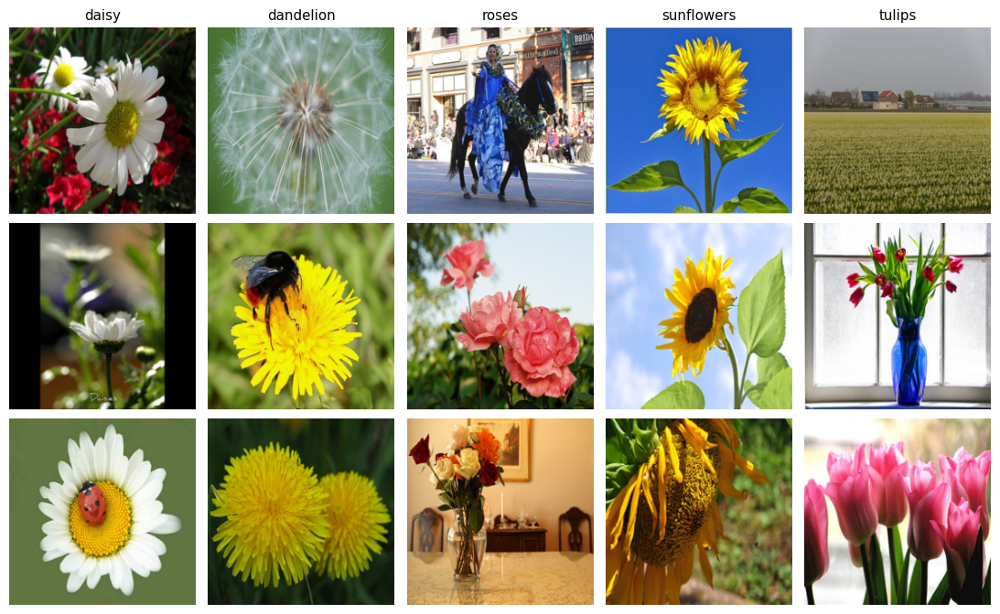

In [5]:
fig,ax=plt.subplots(3,NC,figsize=(2.2*NC,6.8))
for c in range(NC):
    ii=[i for i in tr if y[i]==c][:3]
    for r,i in enumerate(ii):
        ax[r,c].imshow(X[i])
        ax[r,c].axis('off')
        if r==0:
            ax[r,c].set_title(CLASSES[c])
sv('01_sample_images')

In [6]:
class Prep(layers.Layer):
    def call(self,x):
        return tf.reverse(x,axis=[-1])-tf.constant([103.939,116.779,123.68],dtype=x.dtype)

class ChannelAtt(layers.Layer):
    def __init__(self,c,r=16,**kw):
        super().__init__(**kw)
        self.d1=layers.Dense(max(c//r,8),activation='relu')
        self.d2=layers.Dense(c,activation='sigmoid')
    def mc(self,F):
        return self.d2(self.d1(tf.reduce_mean(F,axis=[1,2])))
    def call(self,F):
        return F*self.mc(F)[:,None,None,:]

class SpatialAtt(layers.Layer):
    def __init__(self,ks=7,**kw):
        super().__init__(**kw)
        self.conv=layers.Conv2D(1,ks,padding='same',activation='sigmoid')
    def mp(self,F):
        s=tf.concat([tf.reduce_mean(F,axis=-1,keepdims=True),tf.reduce_max(F,axis=-1,keepdims=True)],axis=-1)
        return self.conv(s)
    def call(self,F):
        return F*self.mp(F)

class SelfAtt(layers.Layer):
    def __init__(self,c,h,w,**kw):
        super().__init__(**kw)
        self.c=c
        self.h=h
        self.w=w
        self.dk=max(c//8,8)
        self.wq=layers.Dense(self.dk,use_bias=False)
        self.wk=layers.Dense(self.dk,use_bias=False)
        self.wv=layers.Dense(max(c//2,8),use_bias=False)
        self.wo=layers.Dense(c,use_bias=False)
    def build(self,input_shape):
        self.gamma=self.add_weight(name='gamma',shape=(1,),initializer='zeros',trainable=True)
        super().build(input_shape)
    def amat(self,F):
        X_=tf.reshape(F,[-1,self.h*self.w,self.c])
        Q=self.wq(X_)
        K=self.wk(X_)
        return tf.nn.softmax(tf.matmul(Q,K,transpose_b=True)/float(np.sqrt(self.dk)),axis=-1)
    def call(self,F):
        X_=tf.reshape(F,[-1,self.h*self.w,self.c])
        A=self.amat(F)
        Y=self.wo(tf.matmul(A,self.wv(X_)))
        return F+self.gamma*tf.reshape(Y,[-1,self.h,self.w,self.c])

class SEAtt(ChannelAtt):
    pass

class ECAAtt(layers.Layer):
    def __init__(self,c,**kw):
        super().__init__(**kw)
        t=int(abs((np.log2(c)+1)/2))
        k=t if t%2==1 else t+1
        self.conv=layers.Conv1D(1,k,padding='same',use_bias=False,activation='sigmoid')
    def mc(self,F):
        z=tf.reduce_mean(F,axis=[1,2])
        return self.conv(z[...,None])[...,0]
    def call(self,F):
        return F*self.mc(F)[:,None,None,:]

class CBAMAtt(layers.Layer):
    def __init__(self,c,r=16,ks=7,**kw):
        super().__init__(**kw)
        self.d1=layers.Dense(max(c//r,8),activation='relu')
        self.d2=layers.Dense(c)
        self.conv=layers.Conv2D(1,ks,padding='same',activation='sigmoid')
    def mc(self,F):
        a=self.d2(self.d1(tf.reduce_mean(F,axis=[1,2])))
        m=self.d2(self.d1(tf.reduce_max(F,axis=[1,2])))
        return tf.nn.sigmoid(a+m)
    def mp(self,F1):
        s=tf.concat([tf.reduce_mean(F1,axis=-1,keepdims=True),tf.reduce_max(F1,axis=-1,keepdims=True)],axis=-1)
        return self.conv(s)
    def sm(self,F):
        return self.mp(F*self.mc(F)[:,None,None,:])[...,0]
    def call(self,F):
        F1=F*self.mc(F)[:,None,None,:]
        return F1*self.mp(F1)

class CoordAtt(layers.Layer):
    def __init__(self,c,h,w,r=32,**kw):
        super().__init__(**kw)
        self.h=h
        self.w=w
        mip=max(8,c//r)
        self.conv1=layers.Conv2D(mip,1)
        self.bn=layers.BatchNormalization()
        self.convh=layers.Conv2D(c,1,activation='sigmoid')
        self.convw=layers.Conv2D(c,1,activation='sigmoid')
    def coords(self,F,training=False):
        xh=tf.reduce_mean(F,axis=2,keepdims=True)
        xw=tf.transpose(tf.reduce_mean(F,axis=1,keepdims=True),[0,2,1,3])
        y=self.conv1(tf.concat([xh,xw],axis=1))
        y=self.bn(y,training=training)
        y=y*tf.nn.relu6(y+3.0)/6.0
        yh,yw=tf.split(y,[self.h,self.w],axis=1)
        ah=self.convh(yh)
        aw=tf.transpose(self.convw(yw),[0,2,1,3])
        return ah,aw
    def cm(self,F):
        ah,aw=self.coords(F,False)
        return tf.reduce_mean(ah*aw,axis=-1)
    def call(self,F,training=None):
        ah,aw=self.coords(F,training)
        return F*ah*aw

def get_base():
    try:
        return keras.applications.ResNet50(include_top=False,weights='imagenet',input_shape=(IMG,IMG,3))
    except Exception:
        b=keras.applications.ResNet50(include_top=False,weights=None,input_shape=(IMG,IMG,3))
        f=glob.glob('/kaggle/input/**/*resnet50*notop*.h5',recursive=True)
        b.load_weights(f[0])
        return b

def block(L,x,s,b):
    p=f'conv{s}_block{b}'
    if b==1:
        sc=L(p+'_0_bn')(L(p+'_0_conv')(x))
    else:
        sc=x
    y=L(p+'_1_relu')(L(p+'_1_bn')(L(p+'_1_conv')(x)))
    y=L(p+'_2_relu')(L(p+'_2_bn')(L(p+'_2_conv')(y)))
    y=L(p+'_3_bn')(L(p+'_3_conv')(y))
    y=L(p+'_add')([sc,y])
    return L(p+'_out')(y)

def build(cfg,ks=KS):
    base=get_base()
    for l in base.layers:
        l.trainable=False
    L=base.get_layer
    inp=keras.Input((IMG,IMG,3))
    x=layers.RandomFlip('horizontal',seed=SEED)(inp)
    x=layers.RandomRotation(0.05,seed=SEED)(x)
    x=layers.RandomZoom(0.1,seed=SEED)(x)
    x=layers.RandomTranslation(0.1,0.1,seed=SEED)(x)
    x=layers.RandomContrast(0.1,seed=SEED)(x)
    x=Prep()(x)
    for n in ['conv1_pad','conv1_conv','conv1_bn','conv1_relu','pool1_pad','pool1_pool']:
        x=L(n)(x)
    names=[]
    shapes=[]
    tin={}
    tout={}
    for si,(s,nb) in enumerate(zip([2,3,4,5],[3,4,6,3])):
        for b in range(1,nb+1):
            x=block(L,x,s,b)
        pos=f'P{si+1}'
        for op in cfg.get(pos,[]):
            c=int(x.shape[-1])
            h=int(x.shape[1])
            w=int(x.shape[2])
            nm=f'{op}_{pos}'
            if op=='ch':
                lay=ChannelAtt(c,RED,name=nm)
            elif op=='sp':
                lay=SpatialAtt(ks,name=nm)
            elif op=='sa':
                lay=SelfAtt(c,h,w,name=nm)
            elif op=='se':
                lay=SEAtt(c,RED,name=nm)
            elif op=='eca':
                lay=ECAAtt(c,name=nm)
            elif op=='cbam':
                lay=CBAMAtt(c,RED,ks,name=nm)
            else:
                lay=CoordAtt(c,h,w,name=nm)
            x2=lay(x)
            tin[nm]=x
            tout[nm]=x2
            shapes.append((nm,tuple(x.shape[1:]),tuple(x2.shape[1:])))
            names.append(nm)
            x=x2
    feat=x
    x=layers.GlobalAveragePooling2D()(x)
    x=layers.Dropout(DROP)(x)
    lg=layers.Dense(NC,name='logits')(x)
    out=layers.Activation('softmax')(lg)
    model=keras.Model(inp,out)
    featm=keras.Model(inp,feat)
    probe=None
    pi={}
    po={}
    if names:
        tl=[]
        ix={}
        for n in names:
            for t,dd in [(tin[n],pi),(tout[n],po)]:
                if id(t) not in ix:
                    ix[id(t)]=len(tl)
                    tl.append(t)
                dd[n]=ix[id(t)]
        probe=keras.Model(inp,tl)
    return dict(model=model,base=base,feat=featm,probe=probe,names=names,shapes=shapes,pi=pi,po=po)

In [7]:
EXP={
'A0':('Baseline',{},KS),
'A1':('Channel Attention',{'P3':['ch']},KS),
'A2':('Spatial Attention',{'P3':['sp']},KS),
'A3':('Channel+Spatial',{'P3':['ch','sp']},KS),
'A4':('Self-Attention',{'P3':['sa']},KS),
'A5':('Combined (Ch+Sp+SA)',{'P3':['ch','sp','sa']},KS),
'B1':('Channel+Spatial',{'P1':['ch','sp']},KS),
'B2':('Channel+Spatial',{'P2':['ch','sp']},KS),
'B4':('Channel+Spatial',{'P4':['ch','sp']},KS),
'M1':('Channel+Spatial',{'P3':['ch','sp'],'P4':['ch','sp']},KS),
'M2':('Channel+Spatial',{'P2':['ch','sp'],'P3':['ch','sp'],'P4':['ch','sp']},KS),
'O1':('Spatial->Channel',{'P3':['sp','ch']},KS),
'K3':('Spatial k=3',{'P3':['sp']},3),
'K5':('Spatial k=5',{'P3':['sp']},5),
'X1':('Squeeze-and-Excitation (SE)',{'P3':['se']},KS),
'X2':('Efficient Channel Attention (ECA)',{'P3':['eca']},KS),
'X3':('CBAM',{'P3':['cbam']},KS),
'X4':('Coordinate Attention',{'P3':['coord']},KS)
}
POS={'A0':'-','A1':'P3','A2':'P3','A3':'P3','A4':'P3','A5':'P3','B1':'P1','B2':'P2','B4':'P4','M1':'P3+P4','M2':'P2+P3+P4','O1':'P3','K3':'P3','K5':'P3','X1':'P3','X2':'P3','X3':'P3','X4':'P3'}
LB={k:f'{EXP[k][0]} [{POS[k]}]' for k in EXP}
RES={}
MC={}

def inf_time(m):
    m.predict(test_ds,verbose=0)
    ts=[]
    for _ in range(3):
        t0=time.perf_counter()
        m.predict(test_ds,verbose=0)
        ts.append(time.perf_counter()-t0)
    return float(np.mean(ts))/len(yte)*1000

def train(key,title,cfg,ks):
    tf.keras.utils.set_random_seed(SEED)
    d=build(cfg,ks)
    m=d['model']
    t0=time.time()
    m.compile(optimizer=keras.optimizers.Adam(LR1),loss=keras.losses.CategoricalCrossentropy(),metrics=['accuracy'],jit_compile=False)
    h1=m.fit(train_ds,validation_data=val_ds,epochs=E1,verbose=2)
    trp1=int(sum(np.prod(tuple(w.shape)) for w in m.trainable_weights))
    for l in d['base'].layers:
        if l.name.startswith('conv5') and not isinstance(l,layers.BatchNormalization):
            l.trainable=True
    m.compile(optimizer=keras.optimizers.Adam(LR2),loss=keras.losses.CategoricalCrossentropy(),metrics=['accuracy'],jit_compile=False)
    h2=m.fit(train_ds,validation_data=val_ds,epochs=E2,verbose=2)
    ttime=time.time()-t0
    pr=m.predict(test_ds,verbose=0)
    yp=pr.argmax(1)
    p,r,f,_=precision_recall_fscore_support(yte,yp,average='macro',zero_division=0)
    hist={q:list(h1.history[q])+list(h2.history[q]) for q in ['accuracy','val_accuracy','loss','val_loss']}
    RES[key]=dict(title=title,acc=float(accuracy_score(yte,yp)),prec=float(p),rec=float(r),f1=float(f),
        trp=int(sum(np.prod(tuple(w.shape)) for w in m.trainable_weights)),trp1=trp1,tot=int(m.count_params()),
        att=int(sum(m.get_layer(n).count_params() for n in d['names'])),it=inf_time(m),hist=hist,pred=yp,prob=pr,
        tloss=float(-np.mean(np.log(pr[np.arange(len(yte)),yte]+1e-12))),shapes=d['shapes'],time=ttime)
    m.save_weights(f'{WTS}/{key}.weights.h5')
    r_=RES[key]
    print(f'[{key}] {title} @ {POS[key]} | test acc={r_["acc"]:.4f} macroF1={r_["f1"]:.4f} | total params={r_["tot"]:,} | attention params={r_["att"]:,} | inference={r_["it"]:.4f} ms/img | time={ttime/60:.2f} min')
    del d,m
    keras.backend.clear_session()
    gc.collect()

def get(key):
    if key not in MC:
        _,cfg,ks=EXP[key]
        d=build(cfg,ks)
        d['model'].load_weights(f'{WTS}/{key}.weights.h5')
        MC[key]=d
    return MC[key]

In [8]:
for key,(ttl,cfg,ks) in EXP.items():
    print('='*100)
    print('Training',key,ttl,'at',POS[key])
    train(key,ttl,cfg,ks)
print('Total training time (min):',(time.time()-START)/60)

Training A0 Baseline at -
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/6
81/81 - 28s - 351ms/step - accuracy: 0.6668 - loss: 0.8936 - val_accuracy: 0.8509 - val_loss: 0.4165
Epoch 2/6
81/81 - 12s - 150ms/step - accuracy: 0.8443 - loss: 0.4390 - val_accuracy: 0.8745 - val_loss: 0.3337
Epoch 3/6
81/81 - 12s - 151ms/step - accuracy: 0.8747 - loss: 0.3464 - val_accuracy: 0.8800 - val_loss: 0.3198
Epoch 4/6
81/81 - 12s - 154ms/step - accuracy: 0.8930 - loss: 0.3017 - val_accuracy: 0.8982 - val_loss: 0.2957
Epoch 5/6
81/81 - 13s - 156ms/step - accuracy: 0.8961 - loss: 0.2787 - val_accuracy: 0.8964 - val_loss: 0.2750
Epoch 6/6
81/81 - 13s - 157ms/step - accuracy: 0.9042 - loss: 0.2608 - val_accuracy: 0.8945 - val_loss: 0.2719
Epoch 1/10
81/81 - 27s - 331ms/step - accuracy: 0.8976 - loss: 0.2874 - val_accuracy: 0.9182 - val_loss: 0.2375
Epoch 2/10
81/81 - 16s - 202ms/step - accuracy: 0.9389 - loss: 0.1794 - val_accuracy: 0.9127 - val_loss: 0.2607
Epoch 3/10
81/81 - 16s - 203ms/st

In [9]:
def tab(keys):
    rows=[]
    for k in keys:
        r=RES[k]
        rows.append({'Key':k,'Model':EXP[k][0],'Position':POS[k],'Accuracy':round(r['acc'],4),'Precision':round(r['prec'],4),'Recall':round(r['rec'],4),'Macro F1':round(r['f1'],4),'Trainable Params':r['trp'],'Total Params':r['tot'],'Attention Params':r['att'],'Inference ms/img':round(r['it'],4)})
    return pd.DataFrame(rows)

print('Feature dimensions immediately before and after each attention module')
for k in EXP:
    for nm,a,b in RES[k]['shapes']:
        print(f'{k:3s} {nm:7s} input={a} output={b}')
print()
print('Main experiment 1: attention-type ablation (P3)')
print(tab(['A0','A1','A2','A3','A4','A5']).to_string(index=False))
print()
print('Main experiment 2: attention-position ablation (Channel->Spatial)')
print(tab(['B1','B2','A3','B4']).to_string(index=False))
print()
print('Main experiment 3: multiple attention positions (Channel->Spatial)')
print(tab(['A3','B4','M1','M2']).to_string(index=False))
print()
print('Main experiment 4: attention order at P3')
print(tab(['A3','O1']).to_string(index=False))
print()
print('Main experiment 5: spatial-attention kernel size at P3')
print(tab(['K3','K5','A2']).rename(columns={'Model':'Spatial Kernel'}).assign(**{'Spatial Kernel':['3x3','5x5','7x7']})[['Spatial Kernel','Accuracy','Macro F1','Inference ms/img']].to_string(index=False))
print()
print('Required main result table')
mk_=['A0','A1','A2','B2','A3','B4','A4']
mt=tab(mk_)
mt['Model']=['Baseline','Channel Attention','Spatial Attention','Channel+Spatial','Channel+Spatial','Channel+Spatial','Self-Attention']
print(mt[['Model','Position','Accuracy','Precision','Recall','Macro F1','Trainable Params','Total Params','Inference ms/img']].to_string(index=False))
full=tab(list(EXP.keys()))
full.to_csv('/kaggle/working/all_results.csv',index=False)
print()
print('All experiments')
print(full.to_string(index=False))

Feature dimensions immediately before and after each attention module
A1  ch_P3   input=(14, 14, 1024) output=(14, 14, 1024)
A2  sp_P3   input=(14, 14, 1024) output=(14, 14, 1024)
A3  ch_P3   input=(14, 14, 1024) output=(14, 14, 1024)
A3  sp_P3   input=(14, 14, 1024) output=(14, 14, 1024)
A4  sa_P3   input=(14, 14, 1024) output=(14, 14, 1024)
A5  ch_P3   input=(14, 14, 1024) output=(14, 14, 1024)
A5  sp_P3   input=(14, 14, 1024) output=(14, 14, 1024)
A5  sa_P3   input=(14, 14, 1024) output=(14, 14, 1024)
B1  ch_P1   input=(56, 56, 256) output=(56, 56, 256)
B1  sp_P1   input=(56, 56, 256) output=(56, 56, 256)
B2  ch_P2   input=(28, 28, 512) output=(28, 28, 512)
B2  sp_P2   input=(28, 28, 512) output=(28, 28, 512)
B4  ch_P4   input=(7, 7, 2048) output=(7, 7, 2048)
B4  sp_P4   input=(7, 7, 2048) output=(7, 7, 2048)
M1  ch_P3   input=(14, 14, 1024) output=(14, 14, 1024)
M1  sp_P3   input=(14, 14, 1024) output=(14, 14, 1024)
M1  ch_P4   input=(7, 7, 2048) output=(7, 7, 2048)
M1  sp_P4   inp

In [10]:
print('Recorded observations for every experiment')
rows=[]
for k in EXP:
    r=RES[k]
    h=r['hist']
    rows.append({'Key':k,'Model':EXP[k][0],'Position':POS[k],'Train Acc':round(h['accuracy'][-1],4),'Val Acc':round(h['val_accuracy'][-1],4),'Test Acc':round(r['acc'],4),'Train Loss':round(h['loss'][-1],4),'Val Loss':round(h['val_loss'][-1],4),'Test Loss':round(r['tloss'],4),'Macro Precision':round(r['prec'],4),'Macro Recall':round(r['rec'],4),'Macro F1':round(r['f1'],4),'Trainable Params':r['trp'],'Total Params':r['tot'],'Inference ms/img':round(r['it'],4),'Train time (min)':round(r['time']/60,2)})
print(pd.DataFrame(rows).to_string(index=False))

Recorded observations for every experiment
Key                             Model Position  Train Acc  Val Acc  Test Acc  Train Loss  Val Loss  Test Loss  Macro Precision  Macro Recall  Macro F1  Trainable Params  Total Params  Inference ms/img  Train time (min)
 A0                          Baseline        -     0.9946   0.9255    0.9256      0.0179    0.4446     0.3617           0.9350        0.9194    0.9250          14963717      23597957            4.0739              4.52
 A1                 Channel Attention       P3     0.9848   0.9255    0.9292      0.0454    0.3126     0.2608           0.9319        0.9270    0.9290          15095877      23730117            4.2284              4.79
 A2                 Spatial Attention       P3     0.9883   0.9255    0.9365      0.0409    0.3007     0.2103           0.9373        0.9385    0.9364          14963816      23598056            4.1457              4.78
 A3                   Channel+Spatial       P3     0.9805   0.9091    0.9292     

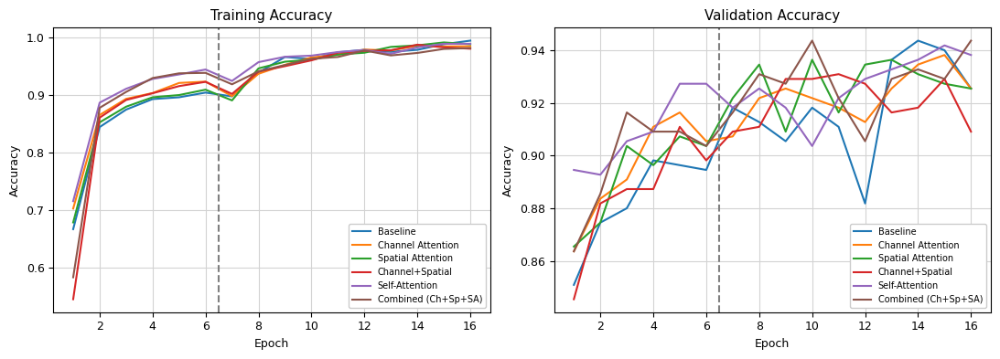

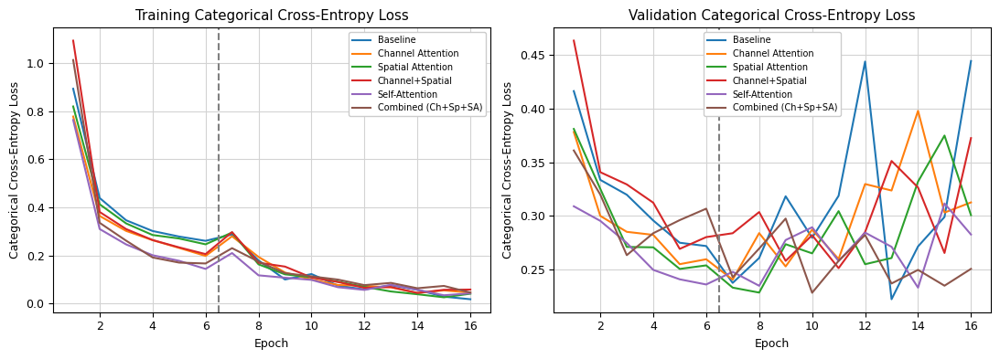

Convergence analysis
              Model  Epochs to 90% val acc  Best val acc  Best epoch  Final train-val acc gap  Val acc std (last 5 epochs)  Final val loss  Min val loss  Epoch-to-epoch val acc roughness
           Baseline                      7        0.9436          14                   0.0691                       0.0227          0.4446        0.2222                            0.0144
  Channel Attention                      4        0.9382          15                   0.0594                       0.0088          0.3126        0.2405                            0.0090
  Spatial Attention                      3        0.9364          10                   0.0629                       0.0041          0.3007        0.2284                            0.0130
    Channel+Spatial                      5        0.9309          11                   0.0714                       0.0074          0.3727        0.2512                            0.0105
     Self-Attention                      3  

In [11]:
SEL=['A0','A1','A2','A3','A4','A5']

def curves(m1,m2,ylabel,fname,keys=None):
    fig,ax=plt.subplots(1,2,figsize=(11,4))
    for k in (keys or SEL):
        h=RES[k]['hist']
        ax[0].plot(range(1,len(h[m1])+1),h[m1],label=EXP[k][0])
        ax[1].plot(range(1,len(h[m2])+1),h[m2],label=EXP[k][0])
    for a,t in zip(ax,['Training','Validation']):
        a.axvline(E1+0.5,color='gray',linestyle='--')
        a.set_title(f'{t} {ylabel}')
        a.set_xlabel('Epoch')
        a.set_ylabel(ylabel)
        a.grid(color='lightgray')
        a.legend(framealpha=1,fontsize=7)
    sv(fname)

curves('accuracy','val_accuracy','Accuracy','02_accuracy_curves')
curves('loss','val_loss','Categorical Cross-Entropy Loss','03_loss_curves')

rows=[]
for k in SEL:
    h=RES[k]['hist']
    va_=np.array(h['val_accuracy'])
    ta_=np.array(h['accuracy'])
    rows.append({'Model':EXP[k][0],'Epochs to 90% val acc':int(np.argmax(va_>=0.90))+1 if (va_>=0.90).any() else -1,'Best val acc':round(va_.max(),4),'Best epoch':int(va_.argmax())+1,'Final train-val acc gap':round(ta_[-1]-va_[-1],4),'Val acc std (last 5 epochs)':round(va_[-5:].std(),4),'Final val loss':round(h['val_loss'][-1],4),'Min val loss':round(min(h['val_loss']),4),'Epoch-to-epoch val acc roughness':round(np.abs(np.diff(va_)).mean(),4)})
print('Convergence analysis')
print(pd.DataFrame(rows).to_string(index=False))

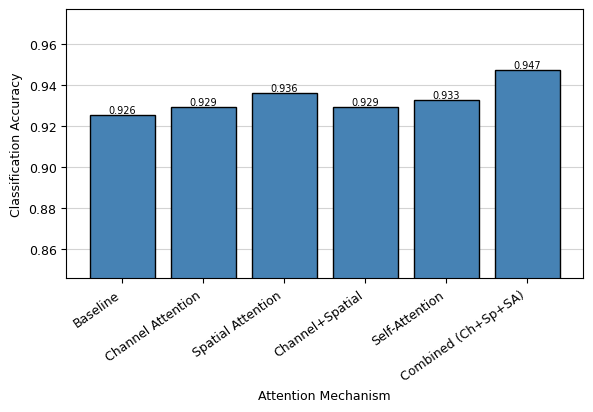

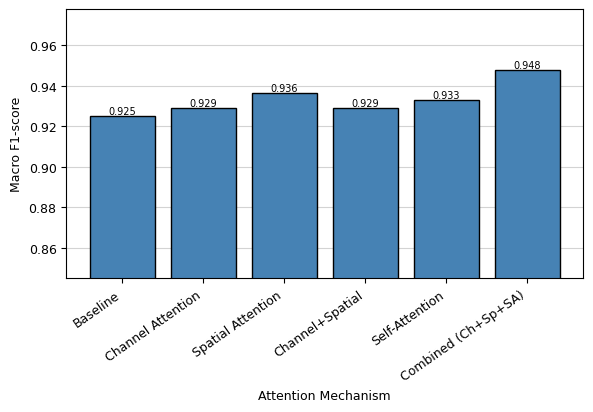

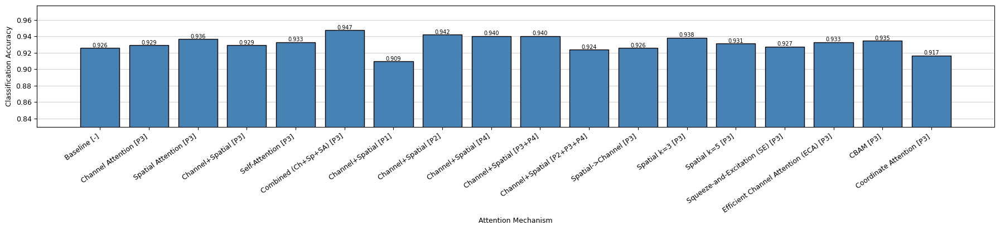

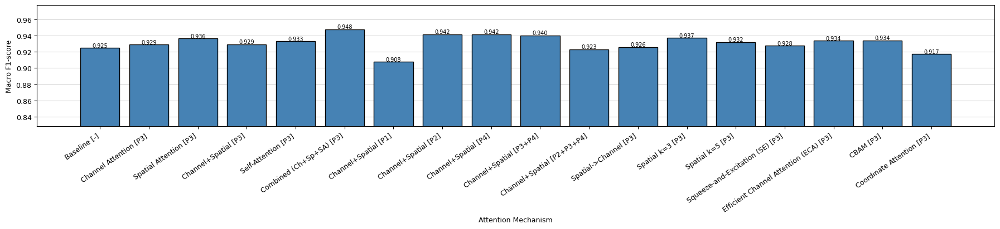

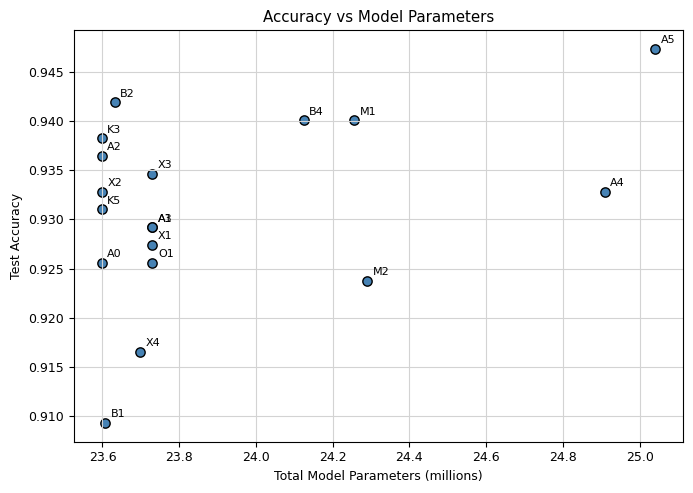

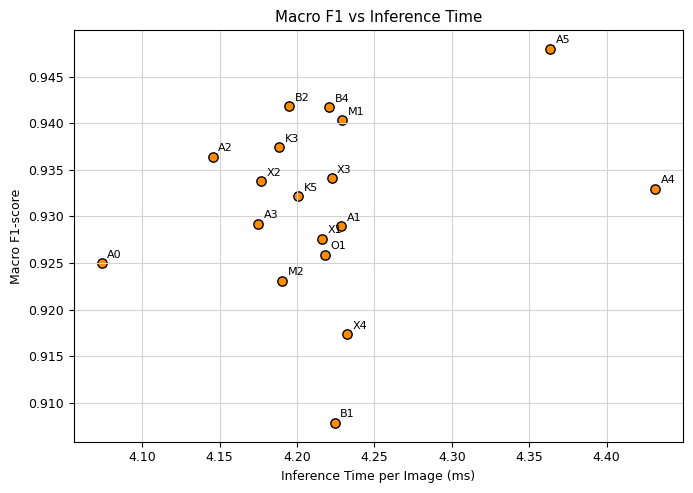

In [12]:
def bars(keys,metric,ylabel,fname,labels=None):
    v=[RES[k][metric] for k in keys]
    fig,ax=plt.subplots(figsize=(max(6,1.0*len(keys)),4.2))
    ax.bar(range(len(keys)),v,color='steelblue',edgecolor='black')
    ax.set_xticks(range(len(keys)))
    ax.set_xticklabels(labels if labels else [EXP[k][0] for k in keys],rotation=35,ha='right')
    ax.set_ylim(max(0,min(v)-0.08),min(1.02,max(v)+0.03))
    for i,t in enumerate(v):
        ax.text(i,t+0.001,f'{t:.3f}',ha='center',fontsize=7)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('Attention Mechanism')
    ax.grid(axis='y',color='lightgray')
    ax.set_axisbelow(True)
    sv(fname)

bars(SEL,'acc','Classification Accuracy','04_bar_accuracy_attention_type')
bars(SEL,'f1','Macro F1-score','05_bar_macro_f1_attention_type')
ALL=list(EXP.keys())
bars(ALL,'acc','Classification Accuracy','06_bar_accuracy_all_experiments',[LB[k] for k in ALL])
bars(ALL,'f1','Macro F1-score','07_bar_macro_f1_all_experiments',[LB[k] for k in ALL])

fig,ax=plt.subplots(figsize=(7,5))
for k in ALL:
    ax.scatter(RES[k]['tot']/1e6,RES[k]['acc'],s=45,color='steelblue',edgecolor='black')
    ax.annotate(k,(RES[k]['tot']/1e6,RES[k]['acc']),textcoords='offset points',xytext=(4,4),fontsize=8)
ax.set_xlabel('Total Model Parameters (millions)')
ax.set_ylabel('Test Accuracy')
ax.set_title('Accuracy vs Model Parameters')
ax.grid(color='lightgray')
sv('08_scatter_accuracy_vs_parameters')

fig,ax=plt.subplots(figsize=(7,5))
for k in ALL:
    ax.scatter(RES[k]['it'],RES[k]['f1'],s=45,color='darkorange',edgecolor='black')
    ax.annotate(k,(RES[k]['it'],RES[k]['f1']),textcoords='offset points',xytext=(4,4),fontsize=8)
ax.set_xlabel('Inference Time per Image (ms)')
ax.set_ylabel('Macro F1-score')
ax.set_title('Macro F1 vs Inference Time')
ax.grid(color='lightgray')
sv('09_scatter_macro_f1_vs_inference_time')

Selected attention-based model (highest test accuracy): A5 Combined (Ch+Sp+SA) [P3]


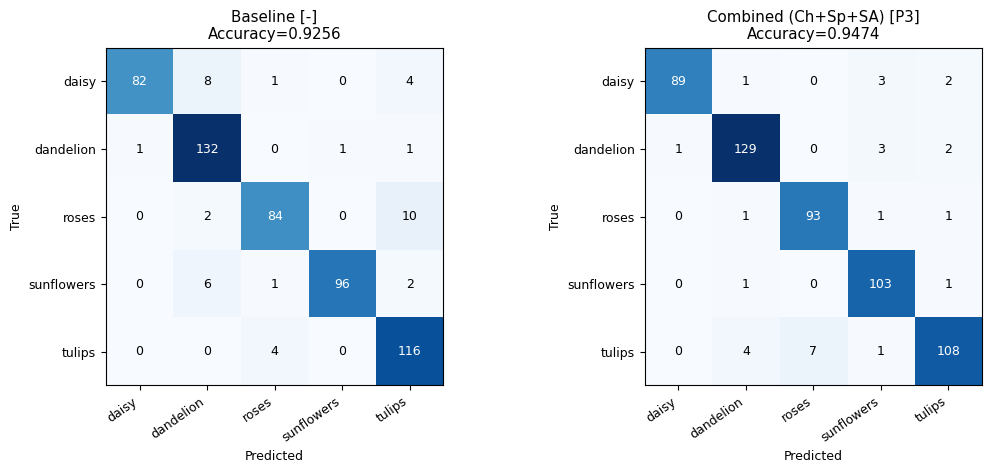

Confusion matrix: Baseline [-]
            daisy  dandelion  roses  sunflowers  tulips
daisy          82          8      1           0       4
dandelion       1        132      0           1       1
roses           0          2     84           0      10
sunflowers      0          6      1          96       2
tulips          0          0      4           0     116
              precision    recall  f1-score   support

       daisy     0.9880    0.8632    0.9213        95
   dandelion     0.8919    0.9778    0.9329       135
       roses     0.9333    0.8750    0.9032        96
  sunflowers     0.9897    0.9143    0.9505       105
      tulips     0.8722    0.9667    0.9170       120

    accuracy                         0.9256       551
   macro avg     0.9350    0.9194    0.9250       551
weighted avg     0.9300    0.9256    0.9256       551

Most frequent confusion: true roses predicted as tulips (10 samples)
Confusion matrix: Combined (Ch+Sp+SA) [P3]
            daisy  dandelion  ro

In [13]:
cand=[k for k in EXP if k!='A0']
BEST=max(cand,key=lambda k:(RES[k]['acc'],RES[k]['f1']))
print('Selected attention-based model (highest test accuracy):',BEST,LB[BEST])

def cmplot(a,k):
    cm=confusion_matrix(yte,RES[k]['pred'],labels=list(range(NC)))
    a.imshow(cm,cmap='Blues')
    a.set_xticks(range(NC))
    a.set_yticks(range(NC))
    a.set_xticklabels(CLASSES,rotation=35,ha='right')
    a.set_yticklabels(CLASSES)
    a.set_xlabel('Predicted')
    a.set_ylabel('True')
    a.set_title(f'{LB[k]}\nAccuracy={RES[k]["acc"]:.4f}')
    for i in range(NC):
        for j in range(NC):
            a.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
    return cm

fig,ax=plt.subplots(1,2,figsize=(11,4.8))
cm0=cmplot(ax[0],'A0')
cmb=cmplot(ax[1],BEST)
sv('10_confusion_matrices')

for k,cm in [('A0',cm0),(BEST,cmb)]:
    print('Confusion matrix:',LB[k])
    print(pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_string())
    print(classification_report(yte,RES[k]['pred'],target_names=CLASSES,digits=4,zero_division=0))
    off=cm.copy()
    np.fill_diagonal(off,0)
    i,j=np.unravel_index(off.argmax(),off.shape)
    print(f'Most frequent confusion: true {CLASSES[i]} predicted as {CLASSES[j]} ({off[i,j]} samples)')

rec0=cm0.diagonal()/cm0.sum(1)
recb=cmb.diagonal()/cmb.sum(1)
print(pd.DataFrame({'Class':CLASSES,'Baseline Recall':rec0.round(4),'Attention Recall':recb.round(4),'Change':(recb-rec0).round(4)}).to_string(index=False))
print('Class benefiting most from attention:',CLASSES[int(np.argmax(recb-rec0))])

In [14]:
def rz(m):
    return tf.image.resize(m[...,None].astype('float32'),(IMG,IMG),method='bilinear').numpy()[...,0]

def rzb(M):
    return np.stack([rz(m) for m in M])

def nm_(m):
    return (m-m.min())/(m.max()-m.min()+1e-8)

def ov(im,m):
    return np.clip(0.5*im/255.0+0.5*plt.get_cmap('jet')(nm_(m))[...,:3],0,1)

def xb(ix):
    return Xte[list(ix)].astype('float32')

def pr_(d,x):
    o=[t.numpy() for t in d['probe'](tf.constant(x),training=False)]
    return {n:o[d['pi'][n]] for n in d['names']},{n:o[d['po'][n]] for n in d['names']}

def sp_map(d,pos,x):
    o=[]
    for i in range(0,len(x),32):
        ins,_=pr_(d,x[i:i+32])
        o.append(d['model'].get_layer('sp_'+pos).mp(tf.constant(ins['sp_'+pos])).numpy()[...,0])
    return np.concatenate(o)

def ch_w(d,pos,x,pre='ch'):
    o=[]
    for i in range(0,len(x),32):
        ins,_=pr_(d,x[i:i+32])
        o.append(d['model'].get_layer(pre+'_'+pos).mc(tf.constant(ins[pre+'_'+pos])).numpy())
    return np.concatenate(o)

def sa_A(d,pos,x):
    o=[]
    for i in range(0,len(x),16):
        ins,_=pr_(d,x[i:i+16])
        o.append(d['model'].get_layer('sa_'+pos).amat(tf.constant(ins['sa_'+pos])).numpy())
    return np.concatenate(o)

def gcam(d,x):
    cs=[]
    ps=[]
    lay=d['model'].get_layer('logits')
    for i in range(0,len(x),32):
        f=d['feat'](tf.constant(x[i:i+32]),training=False)
        with tf.GradientTape() as t:
            t.watch(f)
            lg=lay(tf.reduce_mean(f,axis=[1,2]))
            c=tf.argmax(lg,axis=1)
            sc=tf.gather(lg,c,batch_dims=1)
        g=t.gradient(sc,f)
        w=tf.reduce_mean(g,axis=[1,2])
        cam=tf.nn.relu(tf.reduce_sum(f*w[:,None,None,:],axis=-1))
        cs.append(cam.numpy())
        ps.append(c.numpy())
    return np.concatenate(cs),np.concatenate(ps)

REP=[int(np.where(yte==c)[0][0]) for c in range(NC)]
print('Representative test images (one per class):',REP,[CLASSES[yte[i]] for i in REP])

Representative test images (one per class): [1, 9, 0, 5, 3] ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


Feature tensor before attention (P3): (14, 14, 1024) | after attention: (14, 14, 1024)


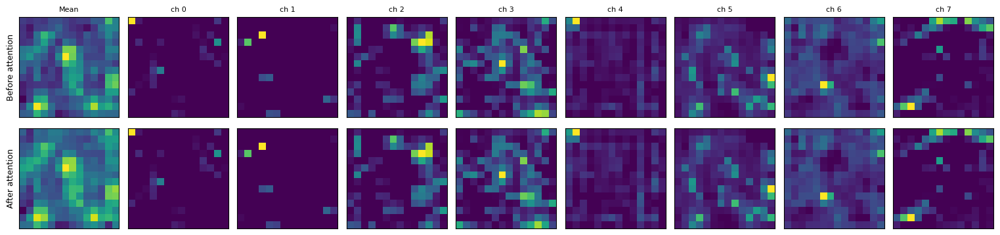

Mean activation before: 0.47930074 after: 0.30324185 | Max before: 19.48499 after: 19.444784


In [15]:
dA3=get('A3')
xr=xb(REP[:1])
ins,outs=pr_(dA3,xr)
fb=ins['ch_P3'][0]
fa=outs['sp_P3'][0]
print('Feature tensor before attention (P3):',fb.shape,'| after attention:',fa.shape)
nc_=8
fig,ax=plt.subplots(2,nc_+1,figsize=(1.7*(nc_+1),3.8))
ax[0,0].imshow(fb.mean(-1),cmap='viridis')
ax[0,0].set_title('Mean',fontsize=8)
ax[1,0].imshow(fa.mean(-1),cmap='viridis')
for c in range(nc_):
    ax[0,c+1].imshow(fb[...,c],cmap='viridis')
    ax[0,c+1].set_title(f'ch {c}',fontsize=8)
    ax[1,c+1].imshow(fa[...,c],cmap='viridis')
for a in ax.ravel():
    a.set_xticks([])
    a.set_yticks([])
ax[0,0].set_ylabel('Before attention')
ax[1,0].set_ylabel('After attention')
sv('11_feature_maps_before_after_attention_P3')
print('Mean activation before:',fb.mean(),'after:',fa.mean(),'| Max before:',fb.max(),'after:',fa.max())

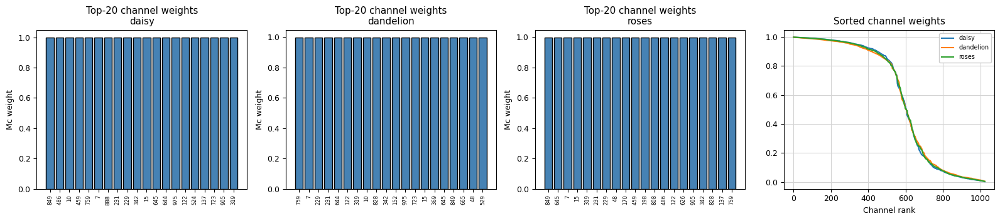

Channel Attention [P3] channel-attention statistics over 256 test images
Channels: 1024 | mean weight: 0.5858 | min: 0.0007 | max: 0.9997
Fraction of weights > 0.5: 0.5876 | mean std across channels: 0.4076 | mean std across images (per channel): 0.0221
Share of total weight in top-20 channels: 0.0333
daisy top-10 channels: [849, 486, 10, 459, 759, 7, 888, 231, 229, 342] weights: [0.9990000128746033, 0.9990000128746033, 0.9990000128746033, 0.9980000257492065, 0.9980000257492065, 0.9980000257492065, 0.9980000257492065, 0.9980000257492065, 0.9980000257492065, 0.9980000257492065]
dandelion top-10 channels: [759, 7, 229, 231, 644, 122, 319, 10, 828, 342] weights: [0.9980000257492065, 0.9980000257492065, 0.996999979019165, 0.996999979019165, 0.996999979019165, 0.996999979019165, 0.996999979019165, 0.996999979019165, 0.996999979019165, 0.996999979019165]
roses top-10 channels: [849, 645, 7, 15, 319, 231, 229, 48, 170, 459] weights: [0.9980000257492065, 0.9980000257492065, 0.9980000257492065,

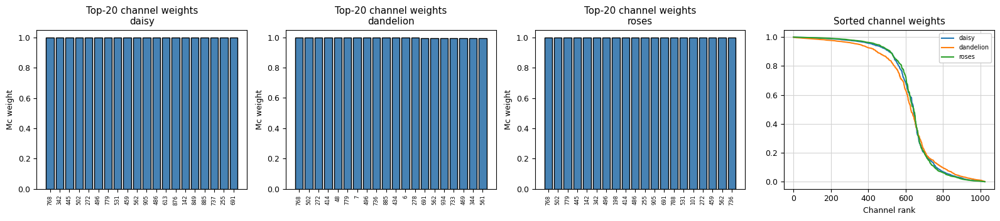

Channel+Spatial [P3] channel-attention statistics over 256 test images
Channels: 1024 | mean weight: 0.6143 | min: 0.0001 | max: 0.9999
Fraction of weights > 0.5: 0.6222 | mean std across channels: 0.413 | mean std across images (per channel): 0.0273
Share of total weight in top-20 channels: 0.0317
daisy top-10 channels: [768, 342, 445, 502, 272, 496, 779, 531, 459, 562] weights: [1.0, 1.0, 0.9990000128746033, 0.9990000128746033, 0.9990000128746033, 0.9990000128746033, 0.9990000128746033, 0.9990000128746033, 0.9990000128746033, 0.9990000128746033]
dandelion top-10 channels: [768, 502, 272, 414, 48, 779, 7, 496, 736, 885] weights: [0.9990000128746033, 0.9990000128746033, 0.9990000128746033, 0.9990000128746033, 0.9980000257492065, 0.9980000257492065, 0.9980000257492065, 0.9980000257492065, 0.996999979019165, 0.996999979019165]
roses top-10 channels: [768, 502, 779, 445, 142, 342, 496, 198, 414, 486] weights: [1.0, 1.0, 1.0, 0.9990000128746033, 0.9990000128746033, 0.9990000128746033, 0.99

In [16]:
def chfig(key,fname):
    d=get(key)
    Wr=ch_w(d,'P3',xb(REP[:3]))
    fig,ax=plt.subplots(1,4,figsize=(16,3.6))
    for i in range(3):
        top=np.argsort(Wr[i])[::-1][:TOPK]
        ax[i].bar(range(TOPK),Wr[i][top],color='steelblue',edgecolor='black')
        ax[i].set_xticks(range(TOPK))
        ax[i].set_xticklabels([str(t) for t in top],rotation=90,fontsize=6)
        ax[i].set_title(f'Top-{TOPK} channel weights\n{CLASSES[yte[REP[i]]]}')
        ax[i].set_ylabel('Mc weight')
    for i in range(3):
        ax[3].plot(np.sort(Wr[i])[::-1],label=CLASSES[yte[REP[i]]])
    ax[3].set_title('Sorted channel weights')
    ax[3].set_xlabel('Channel rank')
    ax[3].grid(color='lightgray')
    ax[3].legend(framealpha=1,fontsize=7)
    sv(fname)
    Wall=ch_w(d,'P3',Xte[:256].astype('float32'))
    srt=np.sort(Wall,axis=1)[:,::-1]
    print(f'{LB[key]} channel-attention statistics over {len(Wall)} test images')
    print('Channels:',Wall.shape[1],'| mean weight:',round(float(Wall.mean()),4),'| min:',round(float(Wall.min()),4),'| max:',round(float(Wall.max()),4))
    print('Fraction of weights > 0.5:',round(float((Wall>0.5).mean()),4),'| mean std across channels:',round(float(Wall.std(1).mean()),4),'| mean std across images (per channel):',round(float(Wall.std(0).mean()),4))
    print(f'Share of total weight in top-{TOPK} channels:',round(float((srt[:,:TOPK].sum(1)/Wall.sum(1)).mean()),4))
    for i in range(3):
        top=np.argsort(Wr[i])[::-1][:10]
        print(CLASSES[yte[REP[i]]],'top-10 channels:',top.tolist(),'weights:',Wr[i][top].round(3).tolist())

chfig('A1','12_channel_attention_weights_A1')
chfig('A3','13_channel_attention_weights_A3')

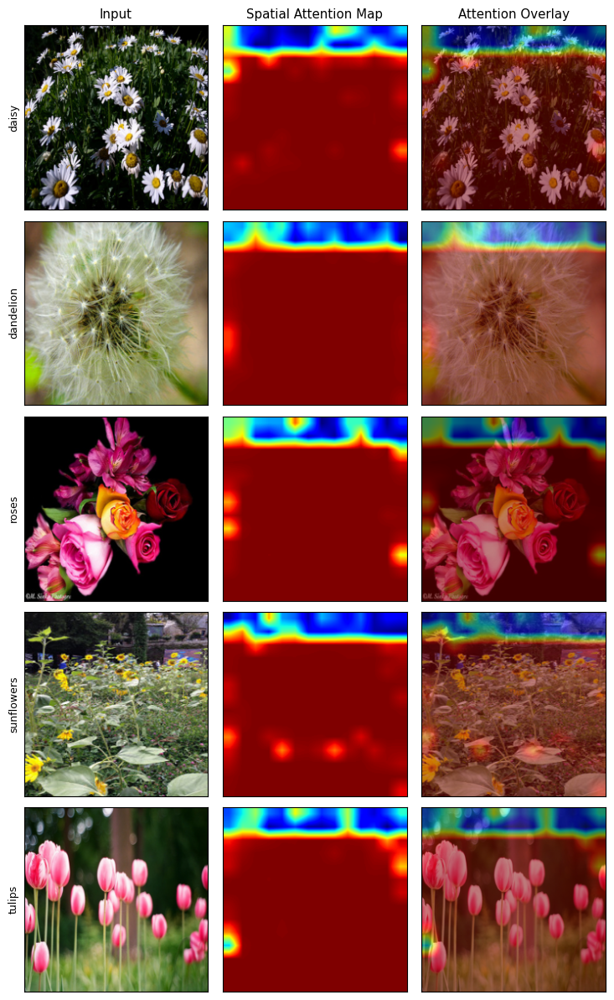

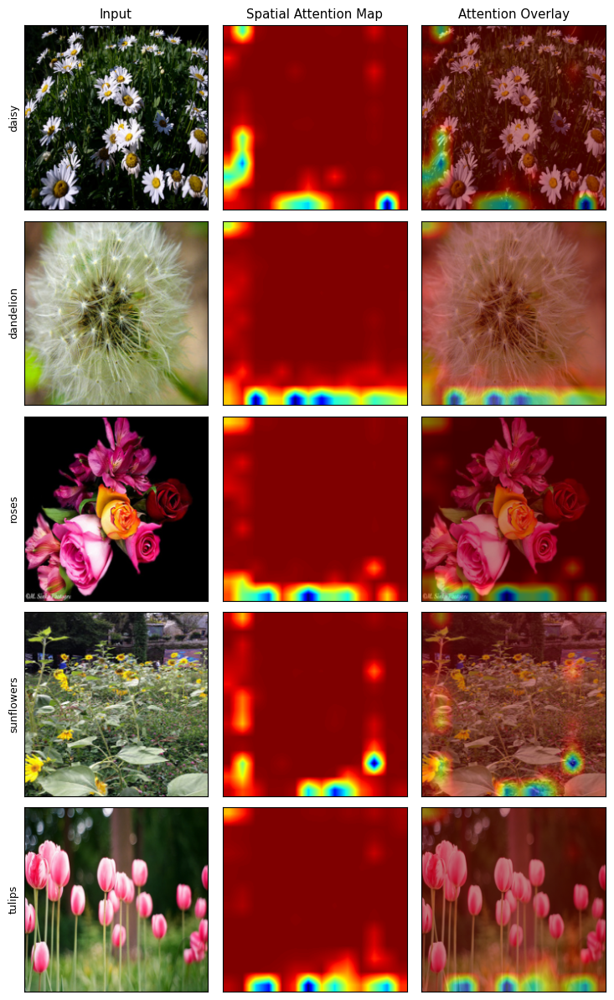

In [18]:
def spfig(key, pos, fname):
    d = get(key)
    M = rzb(sp_map(d, pos, xb(REP)))

    fig, ax = plt.subplots(len(REP), 3, figsize=(7.5, 2.4 * len(REP)))

    for i, j in enumerate(REP):
        ax[i, 0].imshow(Xte[j])
        ax[i, 1].imshow(nm_(M[i]), cmap='jet')
        ax[i, 2].imshow(ov(Xte[j], M[i]))

        ax[i, 0].set_ylabel(CLASSES[yte[j]])

        for a in ax[i]:
            a.set_xticks([])
            a.set_yticks([])

    for a, t in zip(ax[0], ['Input', 'Spatial Attention Map', 'Attention Overlay']):
        a.set_title(t)

    sv(fname)


spfig('A2', 'P3', '14_spatial_attention_A2_P3')
spfig('A3', 'P3', '15_spatial_attention_A3_P3')

Self-attention matrix shape per image: (196, 196) | spatial grid: 14 x 14 | query index (centre): 105


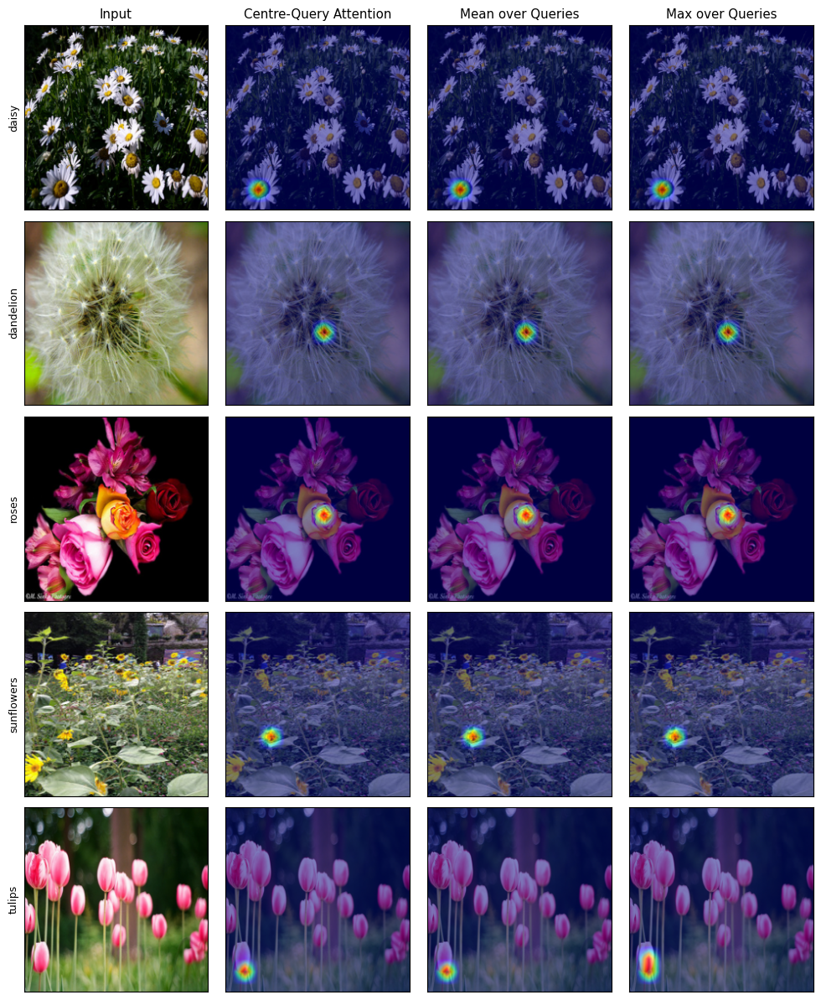

Self-attention statistics: mean attention weight = 0.0051 | uniform value 1/N = 0.0051 | mean max weight per query = 0.99296
Mean attention entropy per query: 0.0197 | maximum possible entropy: 5.2781
Mean attention-weighted distance (grid cells): 6.8964 | mean distance under uniform attention: 7.2808


In [19]:
d=get('A4')
A=sa_A(d,'P3',xb(REP))
hw=int(np.sqrt(A.shape[1]))
qc=(hw//2)*hw+hw//2
print('Self-attention matrix shape per image:',A.shape[1:],'| spatial grid:',hw,'x',hw,'| query index (centre):',qc)
fig,ax=plt.subplots(len(REP),4,figsize=(10,2.4*len(REP)))
for i,j in enumerate(REP):
    q=rz(A[i][qc].reshape(hw,hw))
    mn=rz(A[i].mean(0).reshape(hw,hw))
    mx=rz(A[i].max(0).reshape(hw,hw))
    ax[i,0].imshow(Xte[j])
    ax[i,1].imshow(ov(Xte[j],q))
    ax[i,2].imshow(ov(Xte[j],mn))
    ax[i,3].imshow(ov(Xte[j],mx))
    ax[i,0].set_ylabel(CLASSES[yte[j]])
    for a in ax[i]:
        a.set_xticks([])
        a.set_yticks([])
for a,t in zip(ax[0],['Input','Centre-Query Attention','Mean over Queries','Max over Queries']):
    a.set_title(t)
sv('16_self_attention_response_A4_P3')
print('Self-attention statistics: mean attention weight =',round(float(A.mean()),5),'| uniform value 1/N =',round(1.0/A.shape[1],5),'| mean max weight per query =',round(float(A.max(-1).mean()),5))
ent=-(A*np.log(A+1e-12)).sum(-1).mean()
print('Mean attention entropy per query:',round(float(ent),4),'| maximum possible entropy:',round(float(np.log(A.shape[1])),4))
dist=np.sqrt(((np.arange(A.shape[1])[:,None]//hw-np.arange(A.shape[1])[None,:]//hw)**2)+((np.arange(A.shape[1])[:,None]%hw-np.arange(A.shape[1])[None,:]%hw)**2))
print('Mean attention-weighted distance (grid cells):',round(float((A*dist[None]).sum(-1).mean()),4),'| mean distance under uniform attention:',round(float(dist.mean()),4))

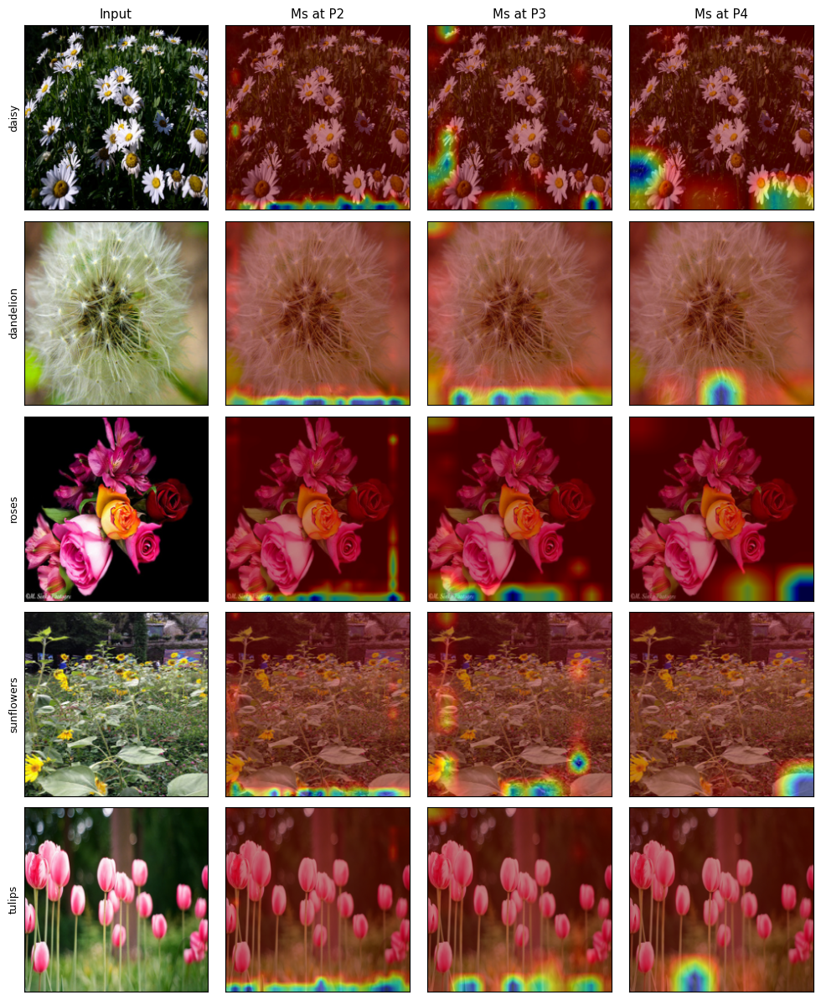

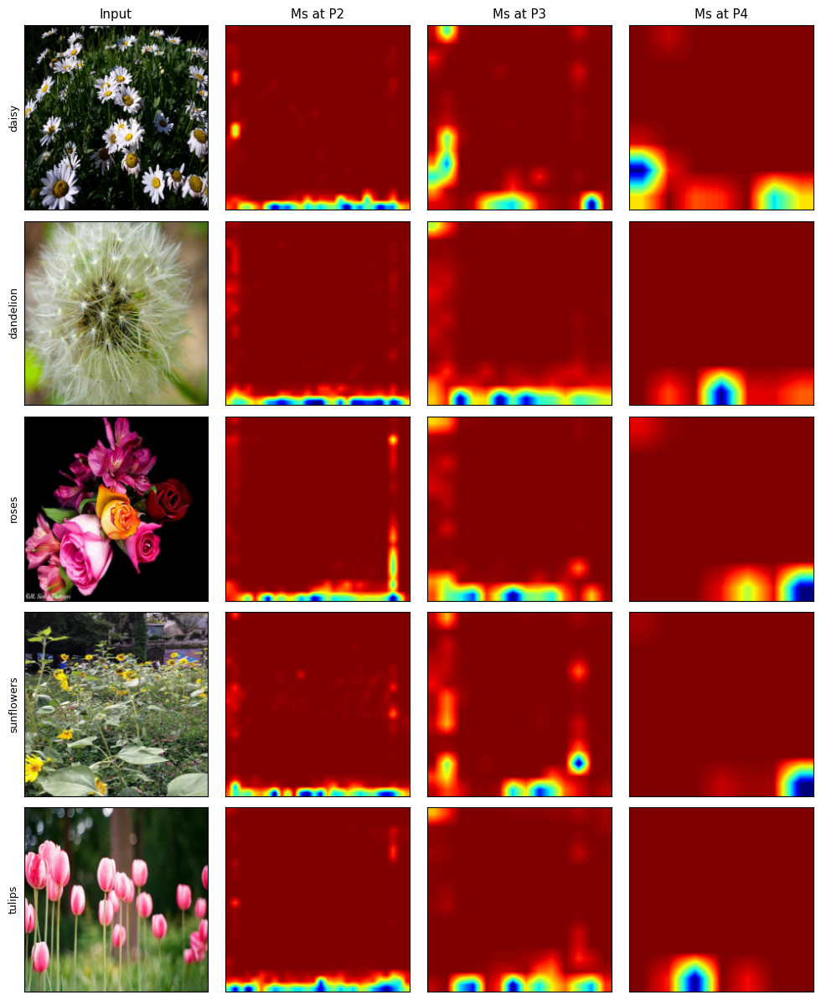

Spatial attention statistics at different positions (100 test images)
Position Map size  Mean value  Std over pixels  Mean max  Mean min  Coverage >0.5
      P2    28x28      0.9790           0.0833       1.0    0.2479         0.9897
      P3    14x14      0.9844           0.0432       1.0    0.6732         0.9996
      P4      7x7      0.9977           0.0107       1.0    0.9313         0.9994


In [20]:
dP={'P2':get('B2'),'P3':get('A3'),'P4':get('B4')}
MP={p:rzb(sp_map(dP[p],p,xb(REP))) for p in dP}
fig,ax=plt.subplots(len(REP),4,figsize=(10,2.4*len(REP)))
for i,j in enumerate(REP):
    ax[i,0].imshow(Xte[j])
    for c,p in enumerate(['P2','P3','P4']):
        ax[i,c+1].imshow(ov(Xte[j],MP[p][i]))
    ax[i,0].set_ylabel(CLASSES[yte[j]])
    for a in ax[i]:
        a.set_xticks([])
        a.set_yticks([])
for a,t in zip(ax[0],['Input','Ms at P2','Ms at P3','Ms at P4']):
    a.set_title(t)
sv('17_spatial_attention_positions_overlay')
fig,ax=plt.subplots(len(REP),4,figsize=(10,2.4*len(REP)))
for i,j in enumerate(REP):
    ax[i,0].imshow(Xte[j])
    for c,p in enumerate(['P2','P3','P4']):
        ax[i,c+1].imshow(nm_(MP[p][i]),cmap='jet')
    ax[i,0].set_ylabel(CLASSES[yte[j]])
    for a in ax[i]:
        a.set_xticks([])
        a.set_yticks([])
for a,t in zip(ax[0],['Input','Ms at P2','Ms at P3','Ms at P4']):
    a.set_title(t)
sv('18_spatial_attention_positions_heatmap')
xs=Xte[:100].astype('float32')
rows=[]
for key,pos in [('B2','P2'),('A3','P3'),('B4','P4')]:
    M=sp_map(get(key),pos,xs)
    rows.append({'Position':pos,'Map size':f'{M.shape[1]}x{M.shape[2]}','Mean value':round(float(M.mean()),4),'Std over pixels':round(float(M.std(axis=(1,2)).mean()),4),'Mean max':round(float(M.max(axis=(1,2)).mean()),4),'Mean min':round(float(M.min(axis=(1,2)).mean()),4),'Coverage >0.5':round(float((M>0.5).mean()),4)})
print('Spatial attention statistics at different positions (100 test images)')
print(pd.DataFrame(rows).to_string(index=False))

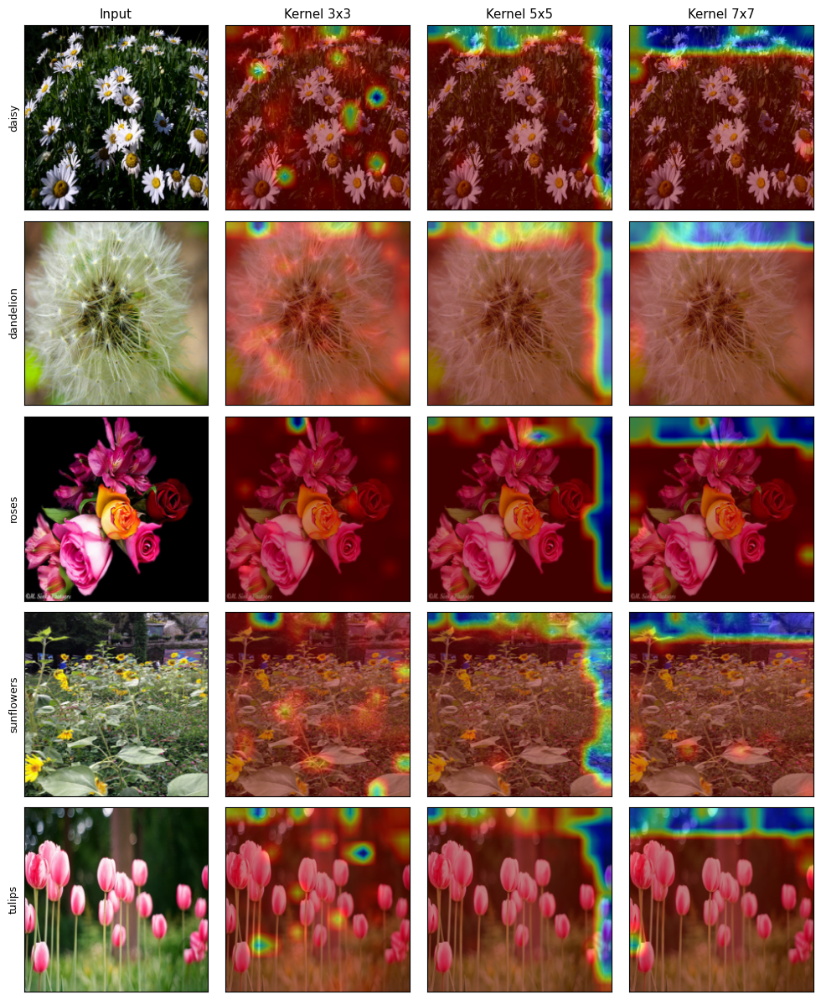

Spatial attention map statistics for different kernel sizes
Kernel  Mean value  Std over pixels  Coverage >0.5  Mean neighbour difference (smoothness)
   3x3      0.9857           0.0312         0.9994                                  0.0158
   5x5      0.8968           0.2401         0.9032                                  0.0649
   7x7      0.8993           0.2424         0.8875                                  0.0506


In [21]:
dK={3:get('K3'),5:get('K5'),7:get('A2')}
MK={k:rzb(sp_map(dK[k],'P3',xb(REP))) for k in dK}
fig,ax=plt.subplots(len(REP),4,figsize=(10,2.4*len(REP)))
for i,j in enumerate(REP):
    ax[i,0].imshow(Xte[j])
    for c,k in enumerate([3,5,7]):
        ax[i,c+1].imshow(ov(Xte[j],MK[k][i]))
    ax[i,0].set_ylabel(CLASSES[yte[j]])
    for a in ax[i]:
        a.set_xticks([])
        a.set_yticks([])
for a,t in zip(ax[0],['Input','Kernel 3x3','Kernel 5x5','Kernel 7x7']):
    a.set_title(t)
sv('19_spatial_attention_kernel_sizes')
rows=[]
for k in [3,5,7]:
    M=sp_map(dK[k],'P3',xs)
    gx=np.abs(np.diff(M,axis=2)).mean()
    gy=np.abs(np.diff(M,axis=1)).mean()
    rows.append({'Kernel':f'{k}x{k}','Mean value':round(float(M.mean()),4),'Std over pixels':round(float(M.std(axis=(1,2)).mean()),4),'Coverage >0.5':round(float((M>0.5).mean()),4),'Mean neighbour difference (smoothness)':round(float((gx+gy)/2),4)})
print('Spatial attention map statistics for different kernel sizes')
print(pd.DataFrame(rows).to_string(index=False))

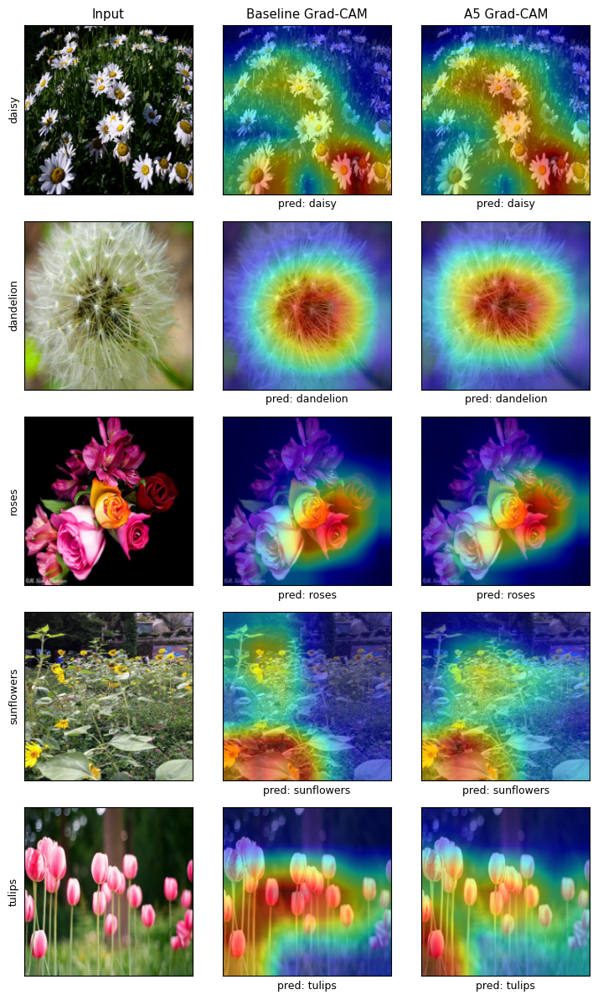

Grad-CAM statistics (128 test images)
            Model Grad-CAM size  Coverage (>0.5)  Compactness (mass in top 10% cells)  Mean activation
         Baseline           7x7           0.2459                               0.3502           0.2857
Channel Attention           7x7           0.2207                               0.3670           0.2697
Spatial Attention           7x7           0.2085                               0.3796           0.2536
  Channel+Spatial           7x7           0.2202                               0.3640           0.2706
   Self-Attention           7x7           0.3005                               0.2797           0.3510


In [23]:
GM=['A0','A1','A2','A3','A4']
GD={k:get(k) for k in GM+[BEST]}
x5=xb(REP)
cb,pb=gcam(GD['A0'],x5)
ca,pa=gcam(GD[BEST],x5)
fig,ax=plt.subplots(len(REP),3,figsize=(7.5,2.4*len(REP)))
for i,j in enumerate(REP):
    ax[i,0].imshow(Xte[j])
    ax[i,1].imshow(ov(Xte[j],rz(cb[i])))
    ax[i,2].imshow(ov(Xte[j],rz(ca[i])))
    ax[i,0].set_ylabel(CLASSES[yte[j]])
    ax[i,1].set_xlabel(f'pred: {CLASSES[pb[i]]}')
    ax[i,2].set_xlabel(f'pred: {CLASSES[pa[i]]}')
    for a in ax[i]:
        a.set_xticks([])
        a.set_yticks([])
for a,t in zip(ax[0],['Input','Baseline Grad-CAM',f'{BEST} Grad-CAM']):
    a.set_title(t)
sv('20_gradcam_baseline_vs_attention')
x100=Xte[:128].astype('float32')
rows=[]
for k in GM:
    c,_=gcam(GD[k],x100)
    cn=np.stack([nm_(q) for q in c])
    fl=cn.reshape(len(cn),-1)
    srt=np.sort(fl,axis=1)[:,::-1]
    nt=max(1,int(np.ceil(0.1*fl.shape[1])))
    rows.append({'Model':EXP[k][0],'Grad-CAM size':f'{c.shape[1]}x{c.shape[2]}','Coverage (>0.5)':round(float((cn>0.5).mean()),4),'Compactness (mass in top 10% cells)':round(float((srt[:,:nt].sum(1)/(fl.sum(1)+1e-8)).mean()),4),'Mean activation':round(float(cn.mean()),4)})
print('Grad-CAM statistics (128 test images)')
print(pd.DataFrame(rows).to_string(index=False))

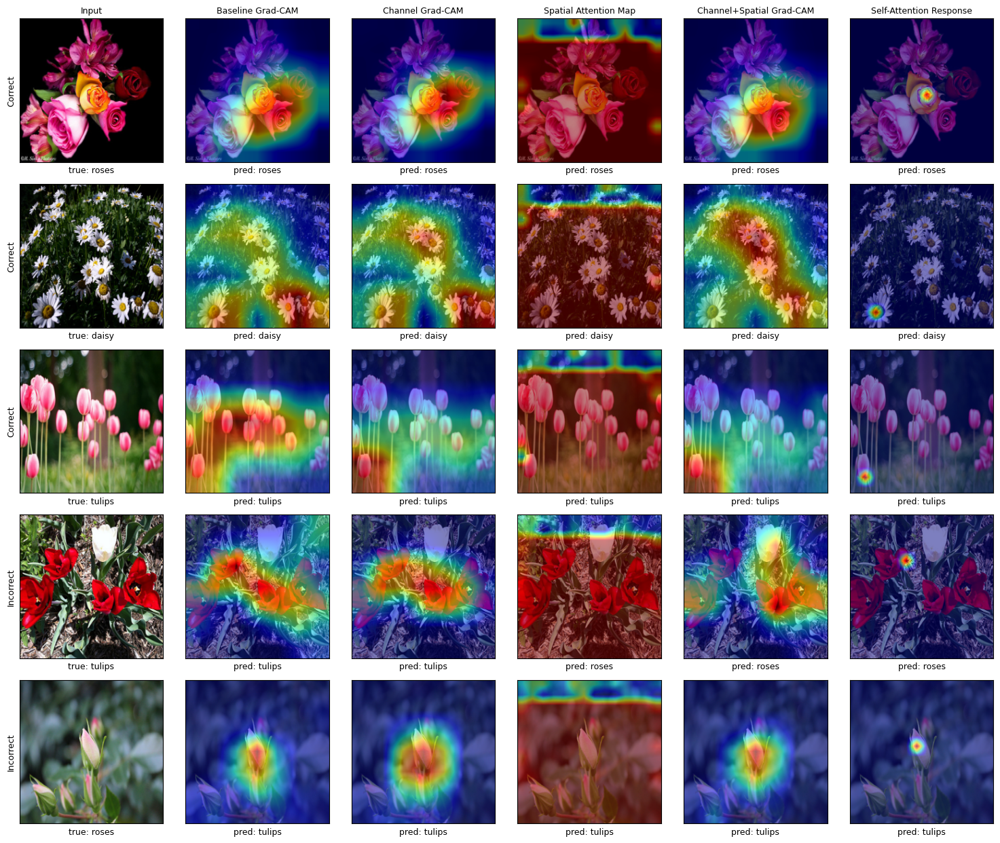

Qualitative comparison images (test indices): [0, 1, 3, 17, 22]
 Index      Type   True Baseline Channel Spatial Channel+Spatial Self-Attention
     0   Correct  roses    roses   roses   roses           roses          roses
     1   Correct  daisy    daisy   daisy   daisy           daisy          daisy
     3   Correct tulips   tulips  tulips  tulips          tulips         tulips
    17 Incorrect tulips   tulips  tulips   roses           roses          roses
    22 Incorrect  roses   tulips  tulips  tulips          tulips         tulips
Channel+Spatial P3 spatial-attention statistics: correct vs incorrect test images
    Group  Count  Mean map value  Coverage >0.5
  Correct    512          0.9844         0.9991
Incorrect     39          0.9827         0.9995


In [24]:
p0=RES['A0']['pred']
p3=RES['A3']['pred']
cor=[i for i in range(len(yte)) if p0[i]==yte[i] and p3[i]==yte[i]]
cs=[]
seen=set()
for i in cor:
    if yte[i] not in seen:
        cs.append(i)
        seen.add(yte[i])
    if len(cs)==3:
        break
wr=[i for i in range(len(yte)) if p3[i]!=yte[i]]
wr+=[i for i in range(len(yte)) if p0[i]!=yte[i] and i not in wr]
conf=RES['A3']['prob'].max(1)
if len(wr)<2:
    wr+=[int(i) for i in np.argsort(conf) if int(i) not in wr][:2-len(wr)]
wr=wr[:2]
QI=cs+wr
xq=xb(QI)
c0,q0=gcam(GD['A0'],xq)
c1,q1=gcam(GD['A1'],xq)
c3,q3=gcam(GD['A3'],xq)
Ms2=rzb(sp_map(GD['A2'],'P3',xq))
Aq=sa_A(GD['A4'],'P3',xq)
hq=int(np.sqrt(Aq.shape[1]))
Mq=rzb(np.stack([a.mean(0).reshape(hq,hq) for a in Aq]))
q2=GD['A2']['model'].predict(xq,verbose=0).argmax(1)
q4=GD['A4']['model'].predict(xq,verbose=0).argmax(1)
tt=['Input','Baseline Grad-CAM','Channel Grad-CAM','Spatial Attention Map','Channel+Spatial Grad-CAM','Self-Attention Response']
fig,ax=plt.subplots(len(QI),6,figsize=(15,2.5*len(QI)))
for r,j in enumerate(QI):
    ax[r,0].imshow(Xte[j])
    ax[r,1].imshow(ov(Xte[j],rz(c0[r])))
    ax[r,2].imshow(ov(Xte[j],rz(c1[r])))
    ax[r,3].imshow(ov(Xte[j],Ms2[r]))
    ax[r,4].imshow(ov(Xte[j],rz(c3[r])))
    ax[r,5].imshow(ov(Xte[j],Mq[r]))
    ax[r,0].set_ylabel(('Correct' if r<len(cs) else 'Incorrect'))
    ax[r,0].set_xlabel(f'true: {CLASSES[yte[j]]}')
    ax[r,1].set_xlabel(f'pred: {CLASSES[q0[r]]}')
    ax[r,2].set_xlabel(f'pred: {CLASSES[q1[r]]}')
    ax[r,3].set_xlabel(f'pred: {CLASSES[q2[r]]}')
    ax[r,4].set_xlabel(f'pred: {CLASSES[q3[r]]}')
    ax[r,5].set_xlabel(f'pred: {CLASSES[q4[r]]}')
    for a in ax[r]:
        a.set_xticks([])
        a.set_yticks([])
for a,t in zip(ax[0],tt):
    a.set_title(t,fontsize=9)
sv('21_qualitative_comparison_correct_and_incorrect')
print('Qualitative comparison images (test indices):',QI)
print(pd.DataFrame({'Index':QI,'Type':['Correct']*len(cs)+['Incorrect']*len(wr),'True':[CLASSES[yte[i]] for i in QI],'Baseline':[CLASSES[v] for v in q0],'Channel':[CLASSES[v] for v in q1],'Spatial':[CLASSES[v] for v in q2],'Channel+Spatial':[CLASSES[v] for v in q3],'Self-Attention':[CLASSES[v] for v in q4]}).to_string(index=False))
ms=sp_map(GD['A3'],'P3',Xte.astype('float32'))
okm=p3==yte
print('Channel+Spatial P3 spatial-attention statistics: correct vs incorrect test images')
print(pd.DataFrame({'Group':['Correct','Incorrect'],'Count':[int(okm.sum()),int((~okm).sum())],'Mean map value':[round(float(ms[okm].mean()),4),round(float(ms[~okm].mean()),4) if (~okm).any() else float('nan')],'Coverage >0.5':[round(float((ms[okm]>0.5).mean()),4),round(float((ms[~okm]>0.5).mean()),4) if (~okm).any() else float('nan')]}).to_string(index=False))

In [25]:
ADD=['X1','X2','X3','X4']
MECH=['A0','A1','A2','A3','A4','X1','X2','X3','X4']
MLAB=['Baseline','Channel','Spatial','Channel+Spatial','Self-Attention','SE','ECA','CBAM','Coordinate']
ML=dict(zip(MECH,MLAB))
print('Additional exploration: comparison of different attention mechanisms (all at P3 on ResNet50)')
order=[('No Attention','A0'),('Channel','A1'),('SE','X1'),('Spatial Attention','A2'),('ECA','X2'),('CBAM','X3'),('Self-Attention','A4'),('Coordinate Attention','X4')]
rows=[]
for lab,k in order:
    r=RES[k]
    rows.append({'Attention':lab,'Accuracy':round(r['acc'],4),'Precision':round(r['prec'],4),'Recall':round(r['rec'],4),'Macro F1':round(r['f1'],4),'Total Params':r['tot'],'Attention Params':r['att'],'Trainable Params':r['trp'],'Inference ms/img':round(r['it'],4),'Acc change vs baseline':round(r['acc']-RES['A0']['acc'],4),'F1 change vs baseline':round(r['f1']-RES['A0']['f1'],4)})
cmp_df=pd.DataFrame(rows)
print(cmp_df.to_string(index=False))
cmp_df.to_csv('/kaggle/working/attention_mechanism_comparison.csv',index=False)
print()
print('Main result table rows for additional attention mechanisms')
ext=tab(ADD)
ext['Model']=['SE (Additional Attention-1)','ECA (Additional Attention-2)','CBAM (Additional Attention-3)','Coordinate Attention (Additional Attention-4)']
print(ext[['Model','Position','Accuracy','Precision','Recall','Macro F1','Trainable Params','Total Params','Attention Params','Inference ms/img']].to_string(index=False))
print()
print('Ranking by accuracy:',[ML[k] for k in sorted(MECH,key=lambda k:-RES[k]['acc'])])
print('Ranking by macro F1:',[ML[k] for k in sorted(MECH,key=lambda k:-RES[k]['f1'])])
print('Ranking by attention parameters (ascending):',[(ML[k],RES[k]['att']) for k in sorted(MECH,key=lambda k:RES[k]['att'])])
print('Ranking by inference time (ascending):',[(ML[k],round(RES[k]['it'],4)) for k in sorted(MECH,key=lambda k:RES[k]['it'])])
rows=[]
for k in MECH:
    h=RES[k]['hist']
    va_=np.array(h['val_accuracy'])
    ta_=np.array(h['accuracy'])
    rows.append({'Model':ML[k],'Epochs to 90% val acc':int(np.argmax(va_>=0.90))+1 if (va_>=0.90).any() else -1,'Best val acc':round(va_.max(),4),'Best epoch':int(va_.argmax())+1,'Final train-val acc gap':round(ta_[-1]-va_[-1],4),'Val acc std (last 5 epochs)':round(va_[-5:].std(),4),'Final val loss':round(h['val_loss'][-1],4),'Min val loss':round(min(h['val_loss']),4)})
print()
print('Convergence analysis for all attention mechanisms')
print(pd.DataFrame(rows).to_string(index=False))
rows=[]
for k in MECH[1:]:
    r=RES[k]
    rows.append({'Model':ML[k],'Attention Params':r['att'],'Params added (% of baseline total)':round(100.0*(r['tot']-RES['A0']['tot'])/RES['A0']['tot'],4),'Inference overhead (ms/img)':round(r['it']-RES['A0']['it'],4),'Accuracy gain per million attention params':round((r['acc']-RES['A0']['acc'])/(max(r['att'],1)/1e6),4)})
print()
print('Complexity overhead relative to baseline')
print(pd.DataFrame(rows).to_string(index=False))

Additional exploration: comparison of different attention mechanisms (all at P3 on ResNet50)
           Attention  Accuracy  Precision  Recall  Macro F1  Total Params  Attention Params  Trainable Params  Inference ms/img  Acc change vs baseline  F1 change vs baseline
        No Attention    0.9256     0.9350  0.9194    0.9250      23597957                 0          14963717            4.0739                  0.0000                 0.0000
             Channel    0.9292     0.9319  0.9270    0.9290      23730117            132160          15095877            4.2284                  0.0036                 0.0040
                  SE    0.9274     0.9293  0.9288    0.9276      23730117            132160          15095877            4.2160                  0.0018                 0.0026
   Spatial Attention    0.9365     0.9373  0.9385    0.9364      23598056                99          14963816            4.1457                  0.0109                 0.0114
                 ECA    0.9328  

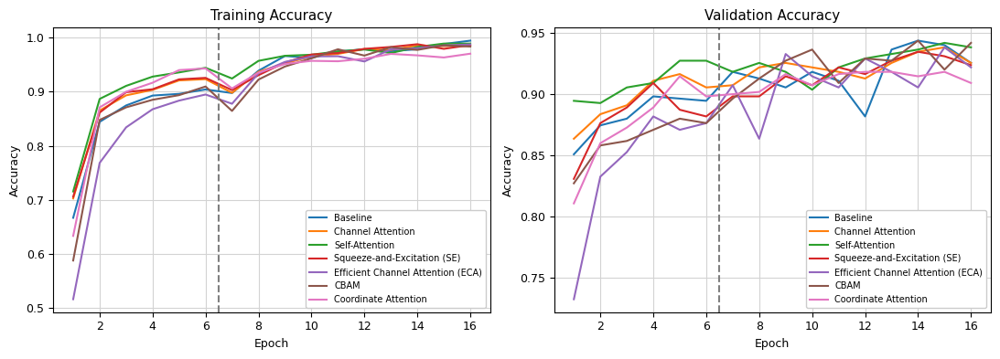

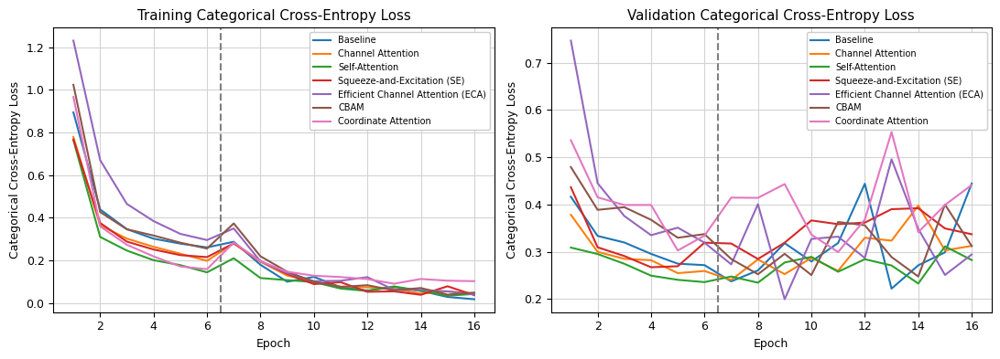

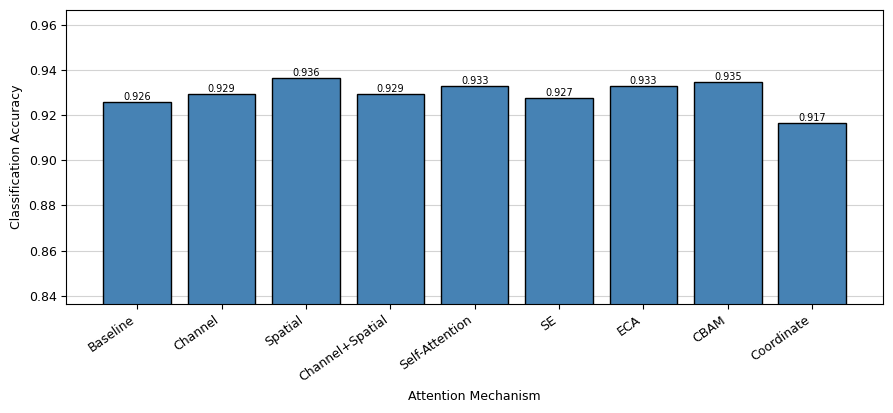

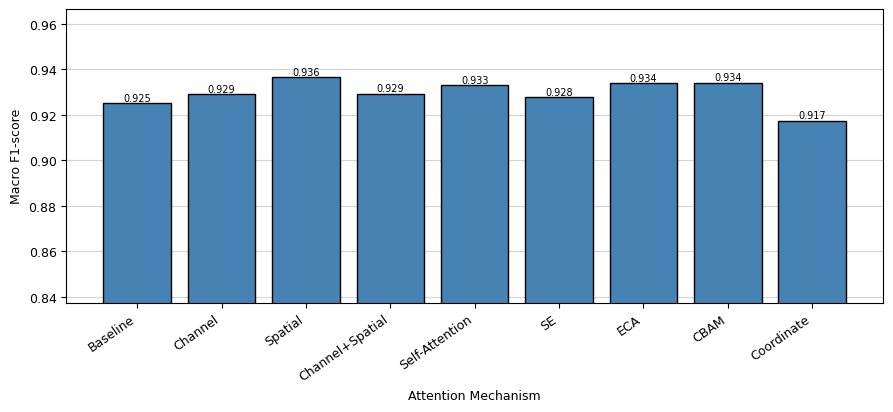

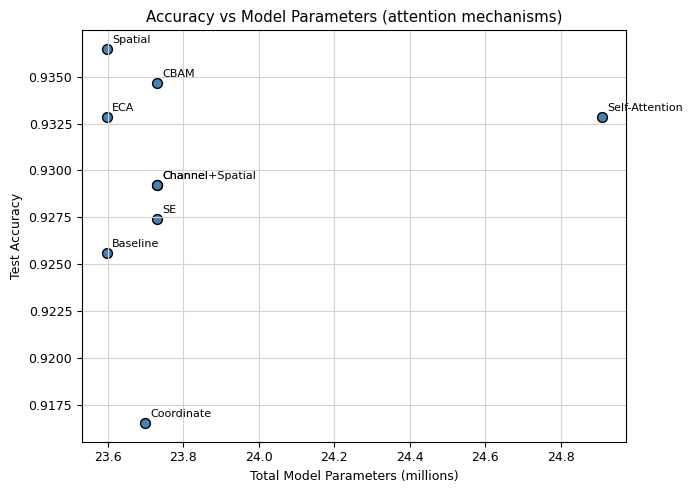

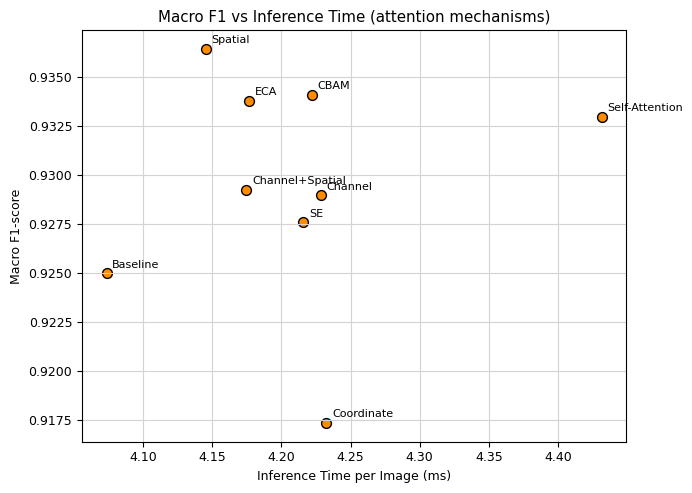

In [26]:
curves('accuracy','val_accuracy','Accuracy','22_accuracy_curves_additional_mechanisms',['A0','A1','A4','X1','X2','X3','X4'])
curves('loss','val_loss','Categorical Cross-Entropy Loss','23_loss_curves_additional_mechanisms',['A0','A1','A4','X1','X2','X3','X4'])
bars(MECH,'acc','Classification Accuracy','24_bar_accuracy_mechanisms',MLAB)
bars(MECH,'f1','Macro F1-score','25_bar_macro_f1_mechanisms',MLAB)
fig,ax=plt.subplots(figsize=(7,5))
for k in MECH:
    ax.scatter(RES[k]['tot']/1e6,RES[k]['acc'],s=50,color='steelblue',edgecolor='black')
    ax.annotate(ML[k],(RES[k]['tot']/1e6,RES[k]['acc']),textcoords='offset points',xytext=(4,4),fontsize=8)
ax.set_xlabel('Total Model Parameters (millions)')
ax.set_ylabel('Test Accuracy')
ax.set_title('Accuracy vs Model Parameters (attention mechanisms)')
ax.grid(color='lightgray')
sv('26_scatter_accuracy_vs_parameters_mechanisms')
fig,ax=plt.subplots(figsize=(7,5))
for k in MECH:
    ax.scatter(RES[k]['it'],RES[k]['f1'],s=50,color='darkorange',edgecolor='black')
    ax.annotate(ML[k],(RES[k]['it'],RES[k]['f1']),textcoords='offset points',xytext=(4,4),fontsize=8)
ax.set_xlabel('Inference Time per Image (ms)')
ax.set_ylabel('Macro F1-score')
ax.set_title('Macro F1 vs Inference Time (attention mechanisms)')
ax.grid(color='lightgray')
sv('27_scatter_macro_f1_vs_inference_time_mechanisms')

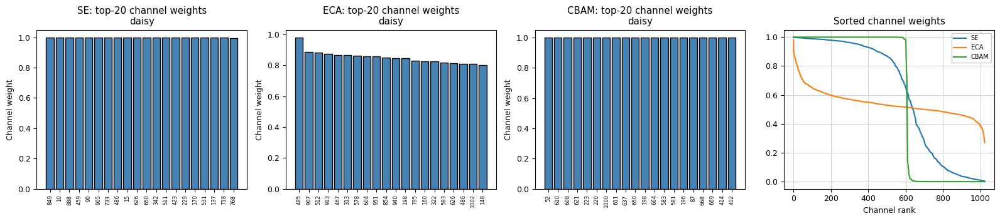

Channel weight statistics for SE, ECA and CBAM (256 test images)
Mechanism  Channels  Mean weight    Min    Max  Fraction >0.5  Std across channels  Std across images  Top-20 share
       SE      1024       0.6160 0.0006 0.9999         0.6222               0.3983             0.0229        0.0316
      ECA      1024       0.5433 0.0872 0.9947         0.7187               0.0765             0.0548        0.0288
     CBAM      1024       0.5933 0.0000 1.0000         0.5927               0.4883             0.0027        0.0329
ECA 1D-convolution kernel size at P3: 5


In [27]:
CHM=[('X1','se','SE'),('X2','eca','ECA'),('X3','cbam','CBAM')]
fig,ax=plt.subplots(1,4,figsize=(16,3.6))
rows=[]
for i,(k,pre,lab) in enumerate(CHM):
    d=get(k)
    Wr=ch_w(d,'P3',xb(REP[:1]),pre)
    top=np.argsort(Wr[0])[::-1][:TOPK]
    ax[i].bar(range(TOPK),Wr[0][top],color='steelblue',edgecolor='black')
    ax[i].set_xticks(range(TOPK))
    ax[i].set_xticklabels([str(t) for t in top],rotation=90,fontsize=6)
    ax[i].set_title(f'{lab}: top-{TOPK} channel weights\n{CLASSES[yte[REP[0]]]}')
    ax[i].set_ylabel('Channel weight')
    ax[3].plot(np.sort(Wr[0])[::-1],label=lab)
    Wall=ch_w(d,'P3',Xte[:256].astype('float32'),pre)
    srt=np.sort(Wall,axis=1)[:,::-1]
    rows.append({'Mechanism':lab,'Channels':Wall.shape[1],'Mean weight':round(float(Wall.mean()),4),'Min':round(float(Wall.min()),4),'Max':round(float(Wall.max()),4),'Fraction >0.5':round(float((Wall>0.5).mean()),4),'Std across channels':round(float(Wall.std(1).mean()),4),'Std across images':round(float(Wall.std(0).mean()),4),f'Top-{TOPK} share':round(float((srt[:,:TOPK].sum(1)/Wall.sum(1)).mean()),4)})
ax[3].set_title('Sorted channel weights')
ax[3].set_xlabel('Channel rank')
ax[3].grid(color='lightgray')
ax[3].legend(framealpha=1,fontsize=7)
sv('28_channel_weights_SE_ECA_CBAM')
print('Channel weight statistics for SE, ECA and CBAM (256 test images)')
print(pd.DataFrame(rows).to_string(index=False))
print('ECA 1D-convolution kernel size at P3:',int(get('X2')['model'].get_layer('eca_P3').conv.kernel_size[0]))

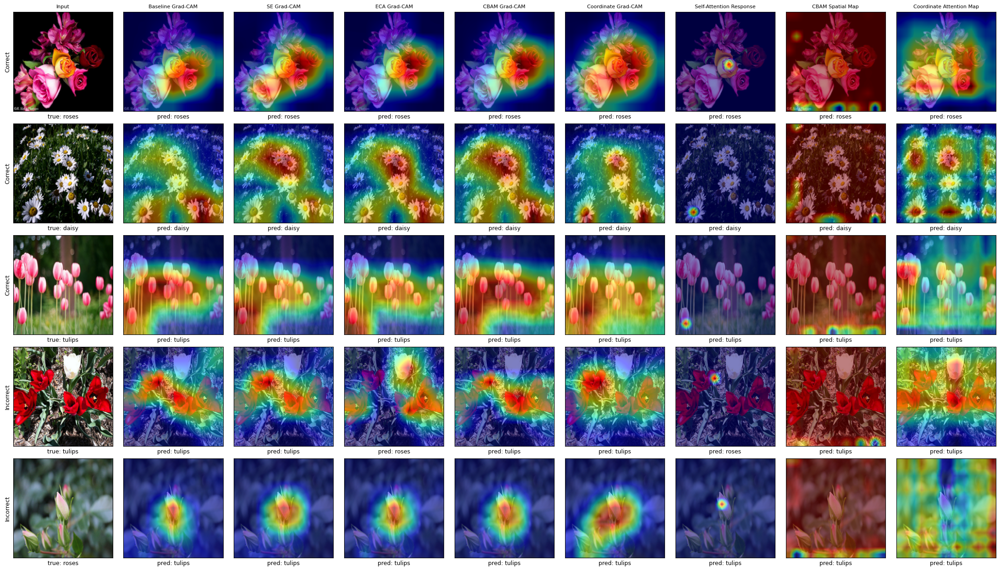

 Index      Type   True Baseline     SE    ECA   CBAM Coordinate Self-Attention
     0   Correct  roses    roses  roses  roses  roses      roses          roses
     1   Correct  daisy    daisy  daisy  daisy  daisy      daisy          daisy
     3   Correct tulips   tulips tulips tulips tulips     tulips         tulips
    17 Incorrect tulips   tulips tulips  roses tulips     tulips          roses
    22 Incorrect  roses   tulips tulips tulips tulips     tulips         tulips
Grad-CAM statistics for additional attention mechanisms (128 test images)
          Model Grad-CAM size  Coverage (>0.5)  Compactness (mass in top 10% cells)  Mean activation
       Baseline           7x7           0.2459                               0.3502           0.2857
             SE           7x7           0.2264                               0.3619           0.2720
            ECA           7x7           0.2291                               0.3762           0.2695
           CBAM           7x7           0.

In [28]:
def lmap(d,name,x,meth):
    o=[]
    for i in range(0,len(x),32):
        ins,_=pr_(d,x[i:i+32])
        o.append(getattr(d['model'].get_layer(name),meth)(tf.constant(ins[name])).numpy())
    return np.concatenate(o)

GX={k:get(k) for k in ADD}
cx={}
qx={}
for k in ADD:
    cx[k],qx[k]=gcam(GX[k],xq)
Mcb=rzb(lmap(GX['X3'],'cbam_P3',xq,'sm'))
Mco=rzb(lmap(GX['X4'],'coord_P3',xq,'cm'))
tt2=['Input','Baseline Grad-CAM','SE Grad-CAM','ECA Grad-CAM','CBAM Grad-CAM','Coordinate Grad-CAM','Self-Attention Response','CBAM Spatial Map','Coordinate Attention Map']
fig,ax=plt.subplots(len(QI),9,figsize=(22,2.5*len(QI)))
for r,j in enumerate(QI):
    ax[r,0].imshow(Xte[j])
    ax[r,1].imshow(ov(Xte[j],rz(c0[r])))
    ax[r,2].imshow(ov(Xte[j],rz(cx['X1'][r])))
    ax[r,3].imshow(ov(Xte[j],rz(cx['X2'][r])))
    ax[r,4].imshow(ov(Xte[j],rz(cx['X3'][r])))
    ax[r,5].imshow(ov(Xte[j],rz(cx['X4'][r])))
    ax[r,6].imshow(ov(Xte[j],Mq[r]))
    ax[r,7].imshow(ov(Xte[j],Mcb[r]))
    ax[r,8].imshow(ov(Xte[j],Mco[r]))
    ax[r,0].set_ylabel('Correct' if r<len(cs) else 'Incorrect')
    ax[r,0].set_xlabel(f'true: {CLASSES[yte[j]]}')
    for c_,pv in zip(range(1,9),[q0[r],qx['X1'][r],qx['X2'][r],qx['X3'][r],qx['X4'][r],q4[r],qx['X3'][r],qx['X4'][r]]):
        ax[r,c_].set_xlabel(f'pred: {CLASSES[pv]}')
    for a in ax[r]:
        a.set_xticks([])
        a.set_yticks([])
for a,t in zip(ax[0],tt2):
    a.set_title(t,fontsize=8)
sv('29_qualitative_comparison_additional_mechanisms')
print(pd.DataFrame({'Index':QI,'Type':['Correct']*len(cs)+['Incorrect']*len(wr),'True':[CLASSES[yte[i]] for i in QI],'Baseline':[CLASSES[v] for v in q0],'SE':[CLASSES[v] for v in qx['X1']],'ECA':[CLASSES[v] for v in qx['X2']],'CBAM':[CLASSES[v] for v in qx['X3']],'Coordinate':[CLASSES[v] for v in qx['X4']],'Self-Attention':[CLASSES[v] for v in q4]}).to_string(index=False))
GSD={'A0':GD['A0'],'X1':GX['X1'],'X2':GX['X2'],'X3':GX['X3'],'X4':GX['X4'],'A3':GD['A3']}
rows=[]
for k in ['A0','X1','X2','X3','X4','A3']:
    c,_=gcam(GSD[k],x100)
    cn=np.stack([nm_(q) for q in c])
    fl=cn.reshape(len(cn),-1)
    srt=np.sort(fl,axis=1)[:,::-1]
    nt=max(1,int(np.ceil(0.1*fl.shape[1])))
    rows.append({'Model':ML[k],'Grad-CAM size':f'{c.shape[1]}x{c.shape[2]}','Coverage (>0.5)':round(float((cn>0.5).mean()),4),'Compactness (mass in top 10% cells)':round(float((srt[:,:nt].sum(1)/(fl.sum(1)+1e-8)).mean()),4),'Mean activation':round(float(cn.mean()),4)})
print('Grad-CAM statistics for additional attention mechanisms (128 test images)')
print(pd.DataFrame(rows).to_string(index=False))
Mcb_all=lmap(GX['X3'],'cbam_P3',xs,'sm')
Mco_all=lmap(GX['X4'],'coord_P3',xs,'cm')
print('CBAM spatial map: mean',round(float(Mcb_all.mean()),4),'std over pixels',round(float(Mcb_all.std(axis=(1,2)).mean()),4),'coverage>0.5',round(float((Mcb_all>0.5).mean()),4))
print('Coordinate attention map: mean',round(float(Mco_all.mean()),4),'std over pixels',round(float(Mco_all.std(axis=(1,2)).mean()),4),'coverage>0.5',round(float((Mco_all>0.5).mean()),4))

In [29]:
print('Saved EPS files:')
for f in sorted(glob.glob(OUT+'/*.eps')):
    print(f,round(os.path.getsize(f)/1e6,2),'MB')
print('Result tables saved to /kaggle/working/all_results.csv and /kaggle/working/attention_mechanism_comparison.csv')
print('Total notebook run time (min):',round((time.time()-START)/60,2))

Saved EPS files:
/kaggle/working/eps_plots/01_sample_images.eps 3.8 MB
/kaggle/working/eps_plots/02_accuracy_curves.eps 0.06 MB
/kaggle/working/eps_plots/03_loss_curves.eps 0.06 MB
/kaggle/working/eps_plots/04_bar_accuracy_attention_type.eps 0.04 MB
/kaggle/working/eps_plots/05_bar_macro_f1_attention_type.eps 0.04 MB
/kaggle/working/eps_plots/06_bar_accuracy_all_experiments.eps 0.06 MB
/kaggle/working/eps_plots/07_bar_macro_f1_all_experiments.eps 0.06 MB
/kaggle/working/eps_plots/08_scatter_accuracy_vs_parameters.eps 0.05 MB
/kaggle/working/eps_plots/09_scatter_macro_f1_vs_inference_time.eps 0.05 MB
/kaggle/working/eps_plots/10_confusion_matrices.eps 1.43 MB
/kaggle/working/eps_plots/11_feature_maps_before_after_attention_P3.eps 2.58 MB
/kaggle/working/eps_plots/12_channel_attention_weights_A1.eps 0.1 MB
/kaggle/working/eps_plots/13_channel_attention_weights_A3.eps 0.1 MB
/kaggle/working/eps_plots/14_spatial_attention_A2_P3.eps 4.42 MB
/kaggle/working/eps_plots/15_spatial_attention_A3_

In [31]:
import shutil

shutil.make_archive('/kaggle/working/plots', 'zip', '/kaggle/working/eps_plots')

'/kaggle/working/plots.zip'